


# Hand gesture recognition using surface EMG signals

**Applied project · Computational Learning (Introduction to Machine Learning with Python)**
MLDS Programme · National University of Colombia

**Authors:** Marina Antolínez Cabrero · Jorge Esau Tierradentro Cruz

## Executive summary

**Problem.** A prosthesis or exoskeleton can only respond smoothly and safely if it is able to infer which gesture the user intends to make. Surface electromyography (EMG) makes this possible, but the signal is noisy and varies from person to person.

**Project question.** To what extent can a classical *machine learning* model recognise six hand and wrist gestures in **people it did not see during training**?

**Data.** *EMG Data for Gestures* (UCI, ID 481): 36 subjects wearing an 8-channel MYO armband, 72 recordings and over 4.2 million readings.

**Method.**

1. Data cleaning.
2. Segmentation into 200 ms windows with 50 per cent overlap.
3. Extraction of 40 time-domain features (RMS, MAV, WL, ZC and SSC per channel).
4. Comparison of a *baseline* model and five other models.
5. Hyperparameter tuning with cross-validation grouped by subject.
6. Single evaluation on 8 held-out subjects.
7. Generalisation analysis (LOSO, per-user calibration, unknown gesture and latency).

### Key results

| Metric | Result | Section |
|---|---|---|
| Baseline (most frequent class), CV per subject | Macro F1 0.049 · accuracy 0.174 | 4.6 |
| Selected model: SVM with RBF kernel (C = 1, γ = 0.03), CV per subject | Macro F1 0.821 ± 0.076 | 4.7 |
| **8 previously unseen test subjects** | **F1-macro 0.829 · accuracy 0.829 · macro AUC 0.955** | 4.10 |
| Leave-One-Subject-Out (36 subjects) | Overall macro F1 score 0.830; per subject, mean 0.815 ± 0.152 (min. 0.315 · max. 0.995) | 4.11 |
| With per-subject normalisation (brief calibration) | Macro F1-score on test 0.829 → 0.909 | 4.11 |
| Inference latency (features + prediction) | 2.73 ms per window, with ~100 ms available | 4.11 |

### Key takeaways

1. **The models significantly outperform the baseline** (macro F1 ≈ 0.82 versus 0.05). The three non-linear models (SVM, Random Forest, Gradient Boosting) perform almost equally well in cross-validation, and slightly better than logistic regression and kNN.
2. **The limiting factor is inter-individual variability, not the number of windows.** With LOSO, the macro-F1 per subject ranges from 0.32 to 0.99, and the learning curves flatten out with a significant gap between training and validation.
3. **Calibration per user helps significantly:** normalising the features within each subject increases the macro-F1 score in the test set from 0.83 to 0.91.
4. **The model is viable in real time**: inference takes ~3 ms compared to the ~100 ms available between windows.
5. **Limitations:** only 36 subjects; the ‘open palm’ class present in 2 of them (excluded); a closed-set classifier; and *offline* evaluation.

> The figures cited in the text are taken from the outputs of the cells in each section; the cells retain the outputs from the original run.

## Contents

1. **Phase 1 · Understanding the business** (project framework, scope, plan and risks, data source and load)
2. **Phase 2 · Understanding the data** (summary, quality, relationship between channels)
3. **Phase 3 · Data preparation** (cleaning, time windows)
4. **Phase 4 · Modelling, evaluation and application** (design, characteristics, selection, evaluation, generalisation)
5. **Conclusions**, limitations and future work

---
# 1. Phase 1 · Understanding the business

## 1.1 Background and problem

The project falls within the field of **assistive robotics and biomedical engineering**. Its beneficiaries are:

* **Users of prostheses and exoskeletons** (people with amputations or reduced mobility), who require their devices to respond smoothly.
* **Clinical and rehabilitation teams**, who use these devices in therapy.
* **Biomechatronics R&D groups**, who design the controllers and need to know which signals, characteristics and models are reliable.

For a device to move smoothly and safely, it must **infer the user’s intended movement**. Surface electromyography (EMG) measures the electrical activity of muscles using electrodes placed on the skin and is one of the most common sources of data for this purpose. However, interpreting it is difficult:

* It is noisy and has low amplitude.
* It varies between individuals (anatomy, muscle strength, subcutaneous fat) and between sessions (electrode placement, sweat, fatigue).
* A classification error results in an unwanted movement, frustration and, in the worst case, a risk of injury or a fall.

| | |
|---|---|
| **Business objective** | To reliably recognise which gesture the user intends to perform, as the basis for controlling an assistive device. |
| **Machine learning objective** | Supervised multi-class classification: using 8-channel EMG signal windows, predict the gesture (rest, clenched fist, wrist flexion, wrist extension, radial deviation and ulnar deviation). |
| **Success criteria** | (1) Clearly outperform the *baselines* (majority class and random). (2) Evaluate accurately using macro F1 and the confusion matrix, as the classes may be imbalanced. (3) Measure the ability to **generalise to unseen subjects** (validation separated by subject), which reflects the real-world scenario of a device being handed to a new user. |
<br>
## 1.2 Scope

The solution is a **reproducible Python pipeline**: loading of EMG records → window segmentation → time-domain feature extraction → training and comparison of classical classifiers → evaluation using subject-based validation.

| Included | Excluded |
|---|---|
| **Offline** classification of hand and wrist gestures | **Real-time** control and latency of the entire system |
| Six gestures: rest, fist, flexion, extension, radial deviation and ulnar deviation | The ‘palm extended’ class (performed by only 2 subjects) and unlabelled data |
| Public 8-channel dataset (MYO armband) | First-hand data acquisition and hardware design |
| Classical ML models with hand-crafted features | *Deep learning* and continuous trajectory estimation |
| Per-subject evaluation and per-class metrics | Integration with simulation or a real device |

The product **is not a final device, but a feasibility study**: a trained model and an analysis of results to help determine which features and models are a good starting point for a prosthetic or exoskeleton controller, and how much performance deteriorates with a new user.
<br>
## 1.3 Risk planning and management

The project was carried out in stages, alongside other modules, with around 20 hours spread over the course and the final day set aside as a buffer (submission on 7 November).

| Stage | Content | Deliverable |
|---|---|---|
| Phase 1 | Background, scope and objective; selection and loading of the dataset | Understanding the business and data loading |
| Phase 2 | Exploration: quality, variable types, relationship between channels | Exploratory analysis |
| Phase 3 | Data cleaning, segmentation into windows | Set of windows ready |
| Phase 4 | Baseline, model comparison, hyperparameters, evaluation | Models compared and evaluated |
| Closure | Conclusions, limitations and presentation | This notebook |

| Anticipated risk | Anticipated mitigation | What happened |
|---|---|---|
| Imbalance: the ‘unlabelled’ class accounts for 64 per cent of the samples | Exclude it, use F1 macro | It was discarded during windowing and class 7 was excluded; the remaining 6 classes were balanced (≈ 16–18 per cent each), so no weighting was required |
| Results inflated by mixing overlapping windows from the same subject | Always separate by subject | The entire evaluation is conducted per subject (hold-out, grouped CV and LOSO), with an explicit check that there are no overlapping subjects |
| Inter-subject variability | Evaluate using unseen subjects and report dispersion | LOSO across the 36 subjects, with dispersion reported per subject (section 4.11) |
| Pre-processing is taking longer than expected | Start with 3 simple features and expand if there is time | These were expanded to 5 features per channel (RMS, MAV, WL, ZC, SSC) |
| Limited time due to exams in other subjects | Prioritise what is essential | Hyperparameter tuning, which was proposed as optional, was also completed |
<br>
## 1.4 Data: source and structure

The data were sourced from the **UCI Machine Learning Repository**, *EMG Data for Gestures* dataset (ID 481, published in 2019, CC BY 4.0 licence): <https://archive.ics.uci.edu/dataset/481/emg+data+for+gestures>.

The data were recorded using a **Thalmic MYO wristband** worn on the forearm of **36 subjects**. Each subject performed 2 sets of 6 or 7 static gestures; each gesture was held for 3 seconds, with a 3-second pause between gestures. The original compressed file is downloaded using `urllib` and decompressed using `zipfile` (**ucimlrepo** is not used because the complete records, organised by subject and by file, are required).

These are **multi-channel time series** with continuous numerical variables and a categorical label. Each file has 10 columns:

| Column | Description | Type |
|---|---|---|
| `time_ms` | Timestamp in milliseconds | Numeric |
| `channel_1` … `channel_8` | EMG signal from each of the 8 sensors on the wristband | Continuous numeric |
| `class` | Gesture: 0 unmarked · 1 rest · 2 clenched fist · 3 wrist flexion · 4 wrist extension · 5 radial deviation · 6 ulnar deviation · 7 extended palm | Categorical, encoded as an integer |

Upon loading, two auxiliary columns, `subject` and `file`, are added; these are required to separate the data by subject later on.

In [6]:
import glob
import io
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 20)

DATASET_URL = "https://archive.ics.uci.edu/static/public/481/emg+data+for+gestures.zip"
DATA_FOLDER = "emg_gestures"


def search_files(root, extension):
    """Returns all files with the given extension within the folder
    (recursively)."""

    return sorted(glob.glob(os.path.join(root, "**", f"*.{extension}"),
                            recursive=True))


def download_dataset(url=DATASET_URL, destination=DATA_FOLDER):
    """Downloads and unpacks the dataset. Does not repeat the download if it already exists."""

    if search_files(destination, "txt"):
        print(f"The dataset is already in '{destination}'.")
        return

    os.makedirs(destination, exist_ok=True)
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response:
        content = response.read()

    with zipfile.ZipFile(io.BytesIO(content)) as external_zip:
        external_zip.extractall(destination)

    # In case the repository contains a zip file inside the zip file
    for inner_zip in search_files(destination, "zip"):
        with zipfile.ZipFile(external_zip) as z:
            z.extractall(os.path.dirname(external_zip))

    n_files = len([a for a in search_files(destination, "txt") if "readme" not in a.lower()])
    print(f"Download complete: {n_files} log files (not including the README).")

download_dataset()
COLUMNS = ["time_ms"] + [f"channel_{i}" for i in range(1, 9)] + ["class"]

GESTURE_NAMES = {
    0: "unlabelled",
    1: "rest",
    2: "clenched fist",
    3: "wrist flexion",
    4: "wrist extension",
    5: "radial deviation",
    6: "ulnar deviation",
    7: "palm extended",
}


def load_dataset(root=DATA_FOLDER):
    """Reads all records and returns a single DataFrame containing the subject
    and the source file."""

    files = [a for a in find_files(root, "txt") if "readme" not in a.lower()]
    if not files:
        raise FileNotFoundError(f"No .txt files found in '{root}'.")

    tables = []
    for path in files:
        table = pd.read_csv(path, sep=r"\s+")
        if table.shape[1] != len(COLUMNS):
            print(f"Warning: {path} is being skipped (it has {table.shape[1]} columns instead of {len(COLUMNS)}).")
            continue
        table.columns = COLUMNS
        table["subject"] = os.path.basename(os.path.dirname(path))
        table["file"] = os.path.basename(path)
        tables.append(table)

    data = pd.concat(tables, ignore_index=True)
    data["subject"] = data["subject"].astype("category")
    return data


data = load_dataset()
data.head()

The dataset is already in 'emg_gestures'.


,time_ms,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6,channel_7,channel_8,class,subject,file
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt


---
# 2. Phase 2 · Understanding the data

## 2.1 General overview

| | |
|---|---|
| Log files | 72 (2 for each of the 36 subjects; the README file is not included) |
| Format | Plain text `.txt`, columns separated by spaces |
| Volume | 4,237,908 rows × 12 columns (10 original columns + `subject` + `file`) |
| Size | 250.82 MB on disk · 642.61 MB in memory |

## 2.2 Data quality

Firstly, the **nominal sampling frequency** and the **class distribution**.

In [7]:
# Estimated sampling frequency based on the timestamp (median within each file)
step_ms = data.groupby("file", observed=True)["time_ms"].apply(lambda t: t.diff().median())
print(f"Median time step: {step_ms.median():.2f} ms  ->  approximate frequency: {1000 / step_ms.median():.0f} Hz")

# Class distribution (the row with a null class is dealt with below and removed in Phase 3)
distribution = data["class"].dropna().astype(int).value_counts().sort_index().rename("samples").to_frame()
distribution["gesture"] = distribution.index.map(GESTURE_NAMES)
distribution["percentage"] = (100 * distribution["samples"] / distribution["samples"].sum()).round(2)
distribution

Median time step: 1.00 ms  ->  approximate frequency: 1000 Hz


,samples,gesture,percentage
class,,,
0,2725157,unlabelled,64.30
1,250055,rest,5.90
2,243193,clenched fist,5.74
3,249494,wrist flexion,5.89
4,251570,wrist extension,5.94
5,251733,radial deviation,5.94
6,253009,ulnar deviation,5.97
7,13696,palm extended,0.32


Almost two-thirds of the readings (64 per cent) belong to class 0 (‘unmarked’), whilst class 7 is in the minority. Let’s see how many subjects each class appears in:

In [9]:
# We identify which subjects performed each gesture
subjects_by_class = (data.dropna(subset=["class"])
                          .assign(clase=lambda d: d["class"].astype(int))
                          .groupby("class", observed=True)["subject"].nunique()
                          .rename("n_subjects").to_frame())
subjects_by_class["gesture"] = subjects_by_class.index.map(GESTURE_NAMES)
subjects_by_class

,n_subjects,gesture
class,,
0.0,36,unlabelled
1.0,36,rest
2.0,36,clenched fist
3.0,36,wrist flexion
4.0,36,wrist extension
5.0,36,radial deviation
6.0,36,ulnar deviation
7.0,2,palm extended


Class 7 (“extended palm”) is performed by only **2 of the 36 subjects**: there is no reliable way to train and assess it with subject-level validation.

Now, checking for missing data, gaps, duplicates and values at the sensor’s limit:

In [10]:
channels = [f"channel_{i}" for i in range(1, 9)]

# Missing values
print(data.isna().sum()[lambda s: s > 0])
print(data[data.isna().any(axis=1)][["file", "time_ms", "class"]])

# Empty files / size of each record
rows_per_file = data.groupby("file", observed=True).size()
print("Rows per file (min / max):", rows_per_file.min(), "/", rows_per_file.max())

# Duplicates
print("Duplicate rows (all columns):", data.duplicated().sum())
print("Duplicates ignoring time:", data.duplicated(subset=channels + ["class", "file"]).sum())

# Values at the sensor’s threshold
saturated = (data[channels].abs() >= 0.00127).sum()
print((100 * saturated / len(data)).round(3))

class    1
dtype: int64
                                  file  time_ms  class
3985214  1_raw_data_10-51_07.04.16.txt    97144    NaN
Rows per file (min / max): 44927 / 79765
Duplicate rows (all columns): 0
Duplicates ignoring time: 3776730
channel_1    0.072
channel_2    0.037
channel_3    0.022
channel_4    0.164
channel_5    0.271
channel_6    0.084
channel_7    0.056
channel_8    0.082
dtype: float64


A quick glance at a complete recording (three channels and the gesture label) shows how the signal increases during active gestures:

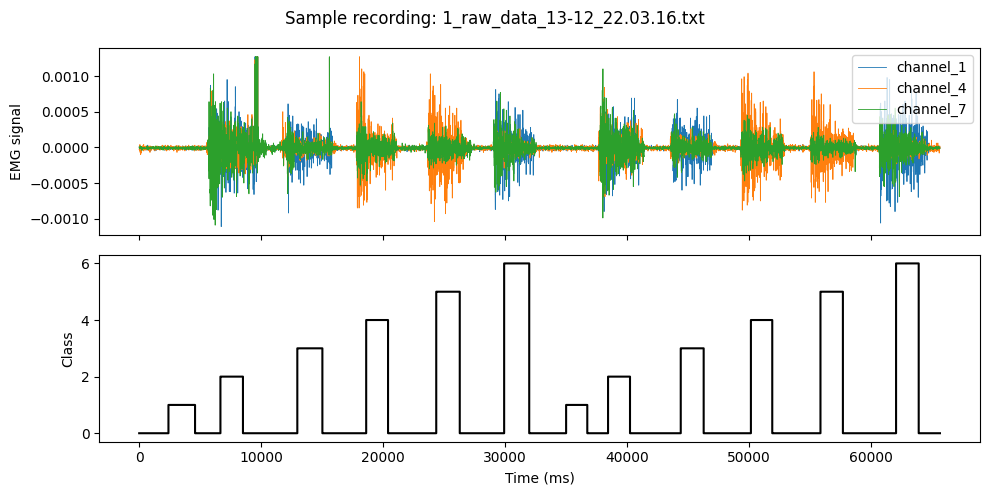

In [12]:
# Quick view of a record: three channels and the gesture label
first_file = data["file"].iloc[0]
sample = data[data["file"] == first_file]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for channel in ["channel_1", "channel_4", "channel_7"]:
    ax1.plot(sample["time_ms"], sample[channel], linewidth=0.6, label=channel)
ax1.set_ylabel("EMG signal")
ax1.legend(loc="upper right")
ax2.step(sample["time_ms"], sample["class"], where="post", color="black")
ax2.set_ylabel("Class")
ax2.set_xlabel("Time (ms)")
fig.suptitle(f"Sample recording: {first_file}")
plt.tight_layout()
plt.show()

### Quality findings and decisions

| Finding | Decision |
|---|---|
| **1 missing value** in `class` (out of over 4.2 million rows) | Remove the row: a label cannot be imputed without introducing noise |
| **64 per cent of unlabelled readings** (class 0) | Exclude them from the model (done when segmenting into windows) |
| **Class 7 found in only 2 out of 36 subjects** | Exclude it from the main model and study it separately as an “unknown gesture” |
| **No exact duplicates**, but ~3.78 million rows repeat the 8 channels from the previous one | This is a reading with no change between consecutive timestamps: it is dealt with in Phase 3 |
| Values at the sensor threshold (\|v\| ≥ 0.00127): 0.02 per cent–0.27 per cent depending on the channel (the most affected, `channel_5`) | Retain and document them: they represent a minimal fraction and there is no reliable way to distinguish them from genuine activation peaks |
| No empty, unreadable or mixed-format files | None |

## 2.3 Relationship between channels

The 8 channels surround the forearm, so some degree of crosstalk between adjacent channels is to be expected. This is measured using Spearman’s correlation:

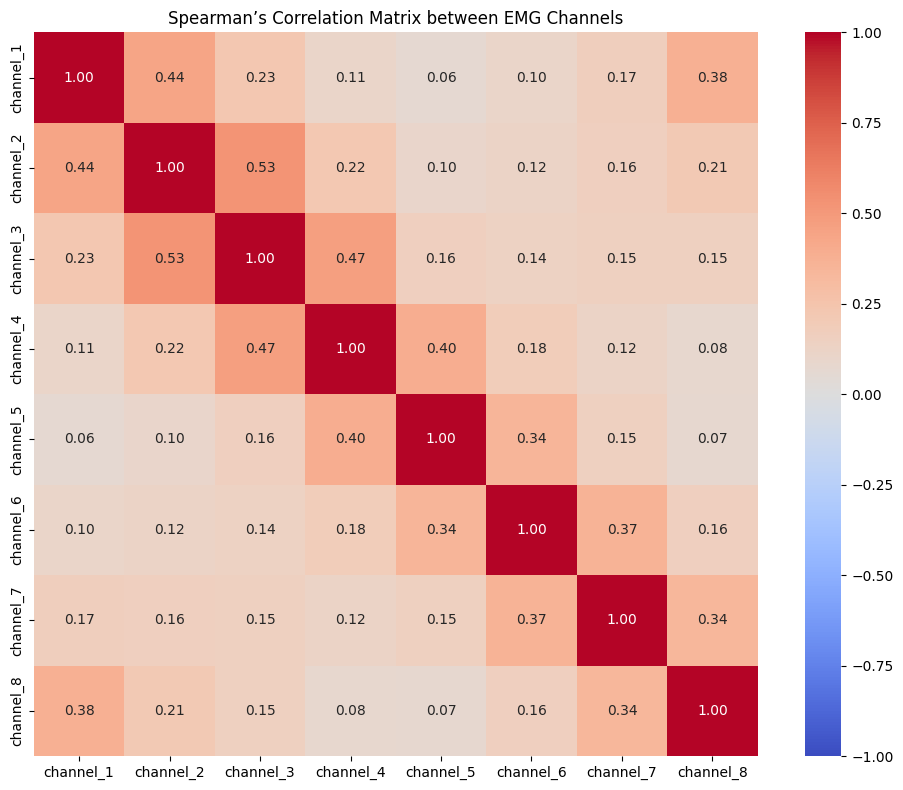

Pairs of channels with high correlation (|r| > 0.8):


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix between the 8 EMG channels
channels = [f"channel_{i}" for i in range(1, 9)]
corr_matrix = data[channels].corr(method='spearman')

# Visualisation using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman’s Correlation Matrix between EMG Channels")
plt.tight_layout()
plt.show()

# Check for pairs with high correlation (> 0.8)
print("Pairs of channels with high correlation (|r| > 0.8):")
for i in range(len(channels)):
    for j in range(i + 1, len(channels)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.8:
            print(f"  {channels[i]} y {channels[j]}: {val:.3f}")

Adjacent channels show moderate correlations, whilst opposite channels show correlations close to zero. **No pair exceeds |r| = 0.8**, so there is no redundancy that would justify removing any channels: all 8 are retained, each providing a different position of the forearm. Rather than selecting channels, each window is summarised using per-channel features (Phase 4).

---
# 3. Phase 3 · Data preparation

Preparation workflow (the figures are taken from the following cells):

```
Raw records (4,237,908 readings)
   │  3.1  remove the row with a null class                      → 4,237,907
   │  3.2  collapse duplicate readings (89.1 per cent)                 →   459,922
   │  3.3  outliers: retained
   │  3.4  types, classes and temporal regularity
   │  3.5  channel integrity
   ▼  3.6  200 ms windows (25 readings), 50 per cent overlap, no class 0  →  10,090 windows × 25 × 8
```

## 3.1 Missing values

The only missing value is in the target variable. The row is **removed** rather than imputed: `class` is a discrete label and guessing it would introduce false labels; furthermore, it is just 1 row out of more than 4.2 million. After removing it, `class` becomes an integer.

In [17]:
# Summary of missing values by column
missing_summary = pd.DataFrame(
    {"Total_Missing": data.isnull().sum(), "Percentage_%": (data.isnull().sum() / len(data)) * 100}
)
print("--- Summary of missing values by column ---")
print(missing_summary)

# Processing: Removing rows with missing values in the target variable 'class'
if data["class"].isnull().sum() > 0:
    rows_before = len(data)
    # Remove rows where “class” is NaN
    data = data.dropna(subset=["class"]).reset_index(drop=True)

    # Ensure the “class” column is of integer type
    data["clasa"] = data["class"].astype(int)

    print(f"\n✅ {rows_before - len(data)} rows with a null “class” value have been removed.")
    print(f"New total number of records: {len(data)}")
else:
    print("\n✅  The dataset is 100% complete. No removals are required.")

--- Summary of missing values by column ---
           Total_Missing  Percentage_%
time_ms                0           0.0
channel_1              0           0.0
channel_2              0           0.0
channel_3              0           0.0
channel_4              0           0.0
channel_5              0           0.0
channel_6              0           0.0
channel_7              0           0.0
channel_8              0           0.0
class                  0           0.0
subject                0           0.0
file                   0           0.0
clasa                  0           0.0

✅  The dataset is 100% complete. No removals are required.


## 3.2 Duplicates and repeated readings

There are no exact duplicate rows or repeated timestamps within a file. However, at the **signal** level, **89.1 per cent** of the readings repeat the 8 channels from the previous reading: the wristband provides new values much less frequently than the nominal 1 kHz frequency of the timestamps, and these values are retained between readings.

Retaining these rows would artificially inflate the statistics for each window. Therefore, **only one row per actual reading** is retained (the first in each block). This reduces the volume from 4.2 million to around 460,000 readings and reveals the **effective frequency** of the signal: ≈ 125 Hz (median interval of 8 ms).

In [20]:
import numpy as np
import pandas as pd

channels = [f"channel_{i}" for i in range(1, 9)]
keys = ["subject", "file"]

# "Classic" duplicates (including time_ms)
print("Exact duplicate rows:", data.duplicated().sum())
print("Duplicates of (subject, file, time_ms):",
      data.duplicated(subset=keys + ["time_ms"]).sum())

# We ensure that the time is strictly increasing within each file
dt = data.groupby(keys, observed=True)["time_ms"].diff()
print("Files with non-increasing time:", int((dt <= 0).sum()))

# SIGNAL duplicates
previous = data.groupby(keys, observed=True)[channels].shift()
repeated = (data[channels] == previous).all(axis=1)      # first row returns False
print(f"\nReadings repeated from the previous one: {repeated.sum():,} ({repeated.mean():.1%})")

# Length of blocks of identical readings
block = (~repeated).cumsum()
print("\nBlock length → number of blocks:’")
print(block.value_counts().value_counts().sort_index().head(10))

# We retain only one row per actual reading (the first in the block)
rows_before = len(data)
data = data[~repeated].reset_index(drop=True)
print(f"\n Rows: {rows_before:,} → {len(data):,}")

# Effective sampling frequency after processing
dt = data.groupby(keys, observed=True)["time_ms"].diff().dropna()
print(f"Median time step:  {dt.median()} ms → effective frequency ≈ {1000/dt.median():.0f} Hz")

Exact duplicate rows: 0
Duplicates of (subject, file, time_ms): 0
Files with non-increasing time: 0

Readings repeated from the previous one: 3,777,985 (89.1%)

Block length → number of blocks:’
count
1     144072
2      42501
3       1967
4       2629
5       5946
6      11215
7      14979
8      15053
9      14161
10      3426
Name: count, dtype: int64

 Rows: 4,237,907 → 459,922
Median time step:  8.0 ms → effective frequency ≈ 125 Hz


## 3.3 Outliers

Standard statistical criteria (Z-score and IQR) flag many readings as outliers. However, in EMG, high-voltage spikes **represent actual muscle contraction**: the final table confirms this, as rows with |Z| > 3 account for between 16 per cent and 32 per cent of the rows for active movements (classes 2 to 7), compared with just 0.1 per cent at rest (class 1). Removing them would destroy precisely the information we wish to classify. Furthermore, the absolute maximum observed (0.00128 V) is the same across all channels, which points to the sensor’s measurement range.

**Decision:** no rows are removed; Z-scores and IQRs are used for descriptive purposes only.

In [21]:
import numpy as np
import pandas as pd

channels = [f"channel_{i}" for i in range(1, 9)]

# Z-score and IQR (descriptive only)
z = np.abs((data[channels] - data[channels].mean()) / data[channels].std())
q1, q3 = data[channels].quantile(0.25), data[channels].quantile(0.75)
iqr = q3 - q1
out_of_iqr = (data[channels] < q1 - 1.5 * iqr) | (data[channels] > q3 + 1.5 * iqr)

summary = pd.DataFrame({
    "Z>3": (z > 3).sum(),
    "% Z>3": ((z > 3).mean() * 100).round(2),
    "IQR 1.5x": out_of_iqr.sum(),
    "% IQR": (out_of_iqr.mean() * 100).round(2),
})
print(summary)

# Actual observed range of the signal (avoiding the assumption of a sensor limit)
print("\nAbsolute maximum observed per channel (V):")
print(data[channels].abs().max())

# We check that the statistical outliers correspond to active gestures
z_outliers = (z > 3).any(axis=1)
print("\n% of rows with at least one |Z| > 3, by class:")
print(z_outliers.groupby(data["class"]).mean().mul(100).round(1))

             Z>3  % Z>3  IQR 1.5x  % IQR
channel_1  12903   2.81     96766  21.04
channel_2  10073   2.19     52303  11.37
channel_3  10123   2.20     59218  12.88
channel_4  13295   2.89     83949  18.25
channel_5  12317   2.68     92387  20.09
channel_6  12869   2.80     84421  18.36
channel_7  11890   2.59     80599  17.52
channel_8  13463   2.93    115327  25.08

Absolute maximum observed per channel (V):
channel_1    0.00128
channel_2    0.00128
channel_3    0.00128
channel_4    0.00128
channel_5    0.00128
channel_6    0.00128
channel_7    0.00128
channel_8    0.00128
dtype: float64

% of rows with at least one |Z| > 3, by class:
class
0.0    11.8
1.0     0.1
2.0    32.3
3.0    24.2
4.0    30.4
5.0    16.3
6.0    20.9
7.0    26.4
dtype: float64


## 3.4 Consistency: types, classes and temporal regularity

The types are standardised (`class` to integer; `subject` and `file` to text), the distribution of classes is reviewed following processing, and the regularity of the time intervals is verified.

* Class 0 remains at ≈ 64 per cent and class 7 appears in only 2 subjects.
* 22 per cent of time intervals exceed twice the median (pauses between gestures and gaps in the recordings). Therefore, when segmenting, windows spanning a time gap are discarded.

In [22]:
import numpy as np
import pandas as pd

keys = ["subject", "file"]

# Type correction
data["class"] = data["class"].astype(int)
data["subject"] = data["subject"].astype(str)
data["file"] = data["file"].astype(str)

# Class distribution
count = data["class"].value_counts().sort_index()
print("--- Class distribution ---")
print(pd.DataFrame({"rows": count, "%": (count / len(data) * 100).round(2)}))

occurrences = data.groupby("class")["subject"].nunique()
print("\nSubjects containing each class:")
print(occurrences)
print(f"Total subjects: {data['subject'].nunique()} | Files: {data['file'].nunique()} "
      f"| Records (subject, file): {data.groupby(keys).ngroups}")

dt = data.groupby(keys)["time_ms"].diff().dropna()
print("\nTime interval (ms): 50th/95th/99th/100th percentiles")
print(dt.quantile([0.50, 0.95, 0.99, 1.0]))
median = dt.median()
jumps = (dt > 2 * median)
print(f"Time jumps > 2×median: {jumps.sum():,} ({jumps.mean():.3%})")

--- Class distribution ---
         rows      %
class               
0      295825  64.32
1       27240   5.92
2       26539   5.77
3       26903   5.85
4       27340   5.94
5       27128   5.90
6       27449   5.97
7        1498   0.33

Subjects containing each class:
class
0    36
1    36
2    36
3    36
4    36
5    36
6    36
7     2
Name: subject, dtype: int64
Total subjects: 36 | Files: 72 | Records (subject, file): 72

Time interval (ms): 50th/95th/99th/100th percentiles
0.50        8.0
0.95       22.0
0.99       29.0
1.00    13827.0
Name: time_ms, dtype: float64
Time jumps > 2×median: 101,374 (22.045%)


## 3.5 Data integrity

Checks are carried out to ensure that no channel is ‘flat’ (zero variance) in any record, that there are no non-finite values, and that the variance of each channel per file is not anomalous compared with the other files (robust z-score, using MAD).

In [23]:
import numpy as np
import pandas as pd

channels = [f"channel_{i}" for i in range(1, 9)]
keys = ["subject", "file"]

# We obtain flat channels and non-finite values
var_arch = data.groupby(keys)[channels].var()
flat = (var_arch == 0)
non_finite = (~np.isfinite(data[channels])).sum().sum()

# We examine the variance (in log) of each file relative to the other files
log_var = np.log10(var_arch.where(var_arch > 0))
median = log_var.median()
mad = (log_var - median).abs().median() * 1.4826
z_rob = (log_var - median) / mad
anomalies = z_rob.abs() > 5

print("--- Inspection of corrupted data ---")
print("Flat channels (variance 0) in any file:", int(flat.sum().sum()))
print("Non-finite values:’", int(non_finite))
print("Anomalous (file, channel) combinations (|z robust| > 5):", int(anomalies.sum().sum()))

if anomalies.any().any():
    print("\nFiles to be checked:")
    print(var_arch[anomalies.any(axis=1)])

--- Inspection of corrupted data ---
Flat channels (variance 0) in any file: 0
Non-finite values:’ 0
Anomalous (file, channel) combinations (|z robust| > 5): 0


No channel, trial or file needs to be discarded. It is established as a rule for future recordings that a channel with zero variance invalidates the trial.

## 3.6 Window segmentation

A classifier cannot operate on a reading-by-reading basis: an isolated reading does not reflect the dynamics of contraction. The time series is transformed into **instances** using a sliding window:

| Parameter | Value | Reason |
|---|---|---|
| Window duration | **200 ms** (25 readings at ≈ 125 Hz) | Standard in surface EMG and acceptable delay for real-time control |
| Overlap | **50 %** (a span of 12 readings) | Makes the most of the data without losing temporal resolution |
| Window class | The dominant one, with **purity ≥ 90 %** | Avoids windows that mix two gestures |
| Exclusions | Class 0 (unlabelled), windows with mixed labels and windows with temporal jumps | Retain only well-defined active gestures |

The result is saved in `ventanas_fase3.npz` (the starting point for Phase 4).

In [26]:
import numpy as np
import pandas as pd

channels = [f"channel_{i}" for i in range(1, 9)]
keys = ["subject", "file"]

# Parameters derived from the EFFECTIVE frequency
median_step_ms = data.groupby(keys)["time_ms"].diff().median()
effective_fs = 1000 / median_step_ms

window_ms = 200
n_window = int(round(window_ms * effective_fs / 1000))     # readings per window
n_step = n_window // 2                                     # 50 % overlap
max_duration_ms = 1.25 * window_ms                         # tolerance for temporal gaps
min_purity = 0.90                                          # minimum % of the dominant class

print(f"Effective frequency ≈ {effective_fs:.0f} Hz → window = {n_window} readings, step = {n_step}")

X, y, subjects, files = [], [], [], []
exclusions = {"class_0": 0, "mixed_label": 0, "time_jump": 0}

for (subj, f), g in data.groupby(keys, sort=False):
    g = g.sort_values("time_ms")
    x = g[channels].to_numpy()
    c = g["class"].to_numpy()
    t = g["time_ms"].to_numpy()

    for ini in range(0, len(g) - n_window + 1, n_step):
        fin = ini + n_window
        if t[fin - 1] - t[ini] > max_duration_ms:
            exclusions["time_jump"] += 1
            continue
        classes, counts = np.unique(c[ini:fin], return_counts=True)
        k = counts.argmax()
        if classes[k] == 0:
            exclusions["class_0"] += 1
            continue
        if counts[k] / n_window < min_purity:
            exclusions["mixed_label"] += 1
            continue
        X.append(x[ini:fin]); y.append(classes[k])
        subjects.append(subj); files.append(f)

X_windows = np.array(X)
y_windows = np.array(y)
subjects_windows = np.array(subjects)
files_windows = np.array (files)

print("\n--- Summary of windowing ---")
print("X:", X_windows.shape, "| y:", y_windows.shape)
print("Discarded windows:", exclusions)
print("\nWindows by class:")
print(pd.Series(y_windows).map(lambda c: c).value_counts().sort_index())
print("\nSubjects with class 7 windows:’",
      len(np.unique(subjects_windows[y_windows == 7])))

Effective frequency ≈ 125 Hz → window = 25 readings, step = 12

--- Summary of windowing ---
X: (10090, 25, 8) | y: (10090,)
Discarded windows: {'class_0': 19889, 'mixed_label': 1129, 'time_jump': 7107}

Windows by class:
1    1701
2    1647
3    1643
4    1686
5    1624
6    1689
7     100
Name: count, dtype: int64

Subjects with class 7 windows:’ 2


In [ ]:
np.savez_compressed("ventanas_fase3.npz", X=X_ventanas, y=y_ventanas, sujetos=sujetos_ventanas, archivos=archivos_ventanas)

There are **10,090 windows** (25 readings × 8 channels) with ≈ 1,600–1,700 windows for each gesture from 1 to 6 and only 100 for gesture 7 (2 subjects): this confirms the decision to exclude it from the main model.

---
# 4. Phase 4 · Modelling, evaluation and application

## 4.1 Problem definition and experimental design

**Problem type: supervised multi-class classification.** Each 200 ms window (8 channels) is assigned to one of the gestures.

| Task type | Applicable? | Justification |
|---|---|---|
| Regression | No | The target variable is categorical |
| **Classification** | **Yes** | There are reliable labels per window and the aim is to recognise the gesture |
| Clustering | Exploratory only | With labels, this is not the appropriate task; PCA and silhouette are used to determine whether the structure is dominated by gestures or subjects |
| Others (outliers, *deep learning*) | No | Outliers are genuine contractions, and with ~10,000 windows of 25 readings, deep learning would carry a high risk of overfitting |

**Key challenge: generalising to unseen subjects.** Overlapping windows from the same person are almost identical copies of one another, so mixing subjects between training and testing would result in an overly optimistic estimate. **The entire experimental design is validated per subject.**


**Models explored**

| Model | Role | Main hyperparameters |
|---|---|---|
| Dummy (most frequent class) | Minimum reference | — |
| Logistic regression | Linear and interpretable baseline | `C` |
| k-nearest neighbours (kNN) | Instance-based | `n_neighbours`, `weights`, `p` |
| SVM with RBF kernel | Leading candidate for EMG gesture recognition | `C`, `gamma` |
| Random Forest | Ensemble (bagging), robust to outliers | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| HistGradientBoosting | Ensemble (boosting), benchmark for tabular data | `learning_rate`, `max_iter`, `max_leaf_nodes`, `l2_regularization` |

**Design decisions**

1. **Subject-based partitioning:** ≈ 20% of subjects are set aside as a **hold-out** set and are not used to select the model or hyperparameters. Cross-validation is performed on the remaining 80% using `StratifiedGroupKFold` (5 partitions), grouping by subject.
2. **Features per window:** 5 time-domain descriptors per channel → **40 variables**. Time-domain only, as the effective frequency (≈ 125 Hz) does not allow for reliable spectral features.
3. **Normalisation:** `StandardScaler` within the `Pipeline` (tuned only using the training data from each partition, with no information leakage). Normalisation by subject is tested as a separate experiment (section 4.11).
4. **Class 7:** excluded from the main model (2 subjects, ~100 windows). The final problem is a **6-gesture** classifier; class 7 is used in section 4.11 as an unknown gesture.
5. **Metrics:** macro-F1 (main), accuracy, balanced accuracy, AUC per class and confusion matrix.

## 4.2 Window loading and exclusion of class 7

In [27]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold, LeaveOneGroupOut,
                                     GridSearchCV, RandomizedSearchCV, cross_validate,
                                     cross_val_predict, validation_curve, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, classification_report, ConfusionMatrixDisplay,
                             silhouette_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
channels = [f"channel_{i}" for i in range(1, 9)]
GESTURE_NAMES = {1: "Rest", 2: "Clenched fist", 3: "Wrist flexion", 4: "Wrist extension",
                  5: "Radial deviation", 6: "Ulnar deviation", 7: "Palm extended"}

# Load the ‘fase3’ file
PATH = "ventanas_fase3.npz"
if os.path.exists(PATH):
    d = np.load(PATH, allow_pickle=False)
    X_windows, y_windows = d["X"], d["y"]
    subjects_windows, files_windows = d["subjects"], d["files"]
print("X:", X_windows.shape, "| y:", y_windows.shape)

# Let’s show the presence of each class per subject to justify the decision regarding class 7
presence = (pd.crosstab(subjects_windows, y_windows) > 0).sum(axis=0)
presence.index = [f"{c} - {GESTURE_NAMES[c]}" for c in presence.index]
print("\nSubjects containing each class:")
print(presence.rename("subjects").to_string())

# We exclude class 7 from the main model
EXCLUDED_CLASSES = [7]
mask = ~np.isin(y_windows, EXCLUDED_CLASSES)
X_all, y_all = X_windows[mask], y_windows[mask]
g_all, arch_all = subjects_windows[mask], files_windows[mask]
X_class7 = X_windows[np.isin(y_windows, EXCLUDED_CLASSES)]
classes = np.sort(np.unique(y_all))
print(f"\nWindows after excluding class 7: {len(y_all):,} | classes: {[int(c) for c in classes]} "
      f"| subjects: {len(np.unique(g_all))}")

X: (10090, 25, 8) | y: (10090,)

Subjects containing each class:
1 - Rest                36
2 - Clenched fist       36
3 - Wrist flexion       36
4 - Wrist extension     36
5 - Radial deviation    36
6 - Ulnar deviation     36
7 - Palm extended        2

Windows after excluding class 7: 9,990 | classes: [1, 2, 3, 4, 5, 6] | subjects: 36


## 4.3 Analysis by subject and gesture

**Samples by subject and class.** All subjects perform all six gestures, with a similar number of windows across the gestures.

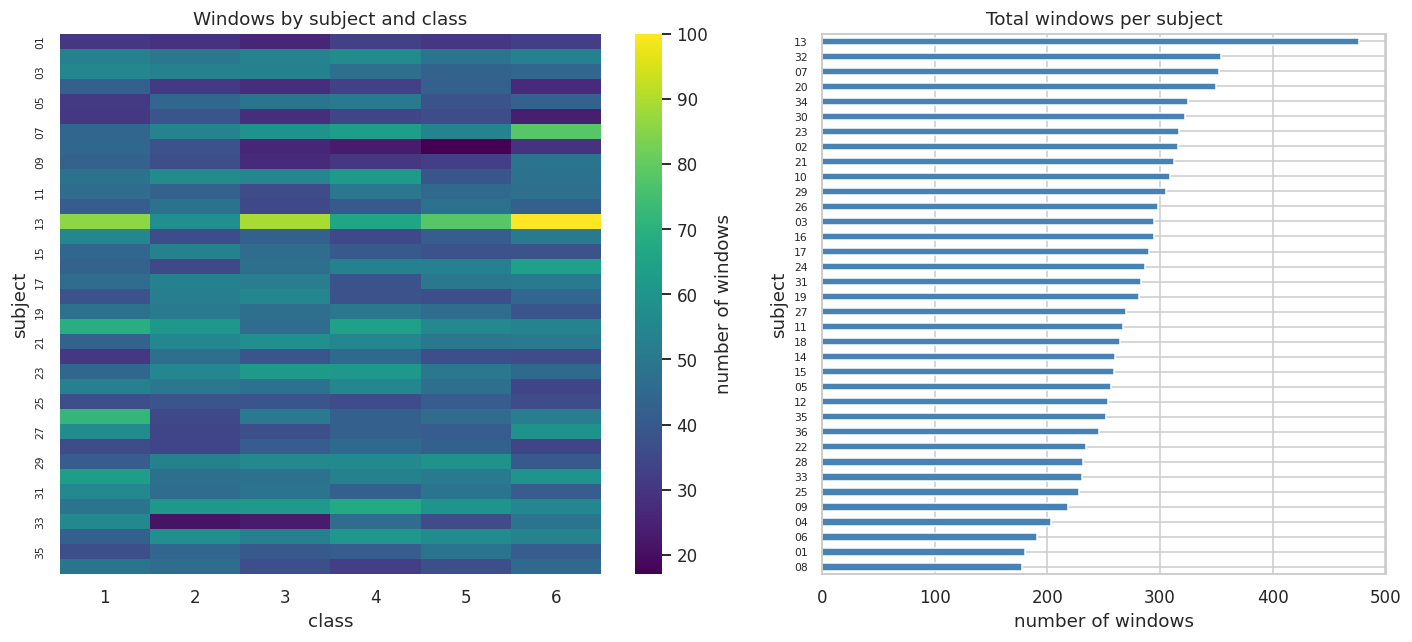

In [28]:
table = pd.crosstab(pd.Series(g_all, name="subject"), pd.Series(y_all, name="class"))
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(table, cmap="viridis", ax=ax[0], cbar_kws={"label": "number of windows"})
ax[0].set_title("Windows by subject and class"); ax[0].tick_params(axis="y", labelsize=7)
table.sum(axis=1).sort_values().plot.barh(ax=ax[1], color="steelblue")
ax[1].set_title("Total windows per subject"); ax[1].set_xlabel("number of windows")
ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

**Example gesture signals** (a 200 ms window from the same subject, all 8 channels and the same vertical scale):

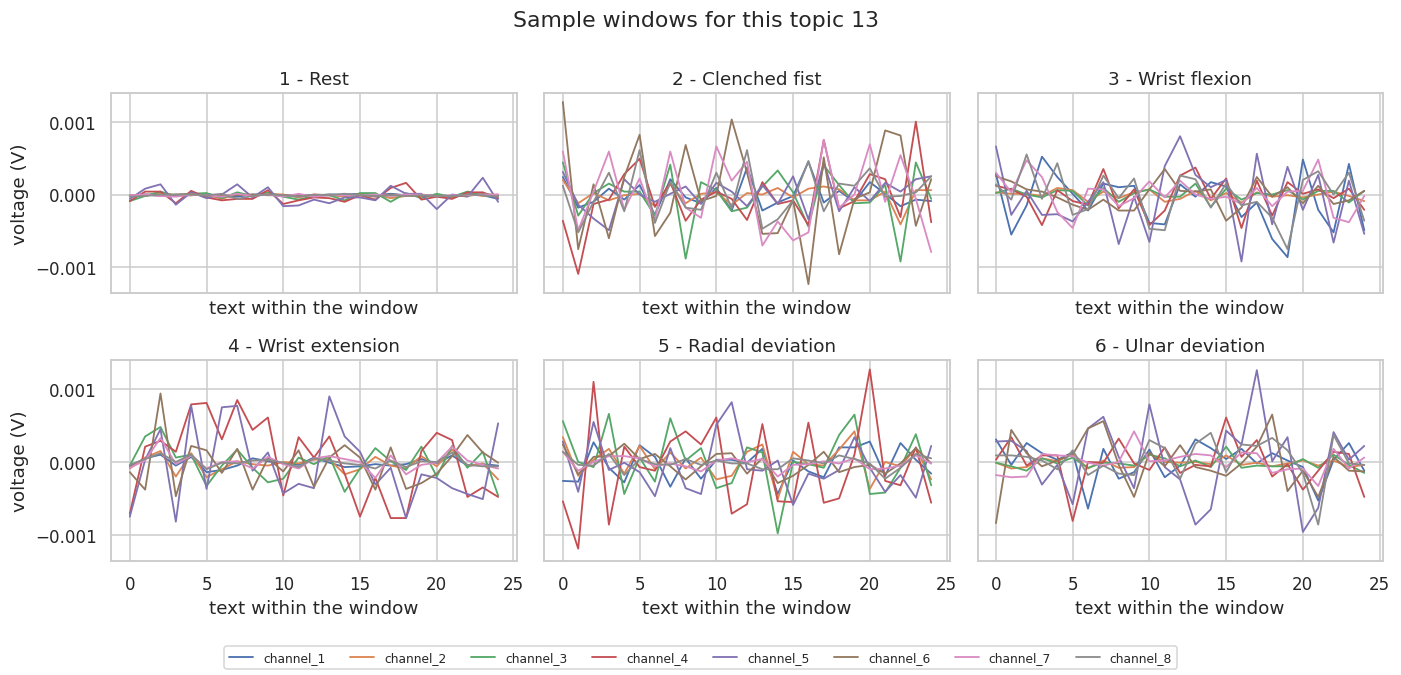

In [29]:
suj_ej = pd.Series(g_all).value_counts().index[0]          # the subject with the most windows
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), classes):
    idx = np.where((g_all == suj_ej) & (y_all == c))[0][0]
    for k in range(8):
        ax.plot(X_all[idx][:, k], lw=1.2, label=channels[k] if c == classes[0] else None)
    ax.set_title(f"{c} - {GESTURE_NAMES[c]}"); ax.set_xlabel("text within the window")
axes[0, 0].set_ylabel("voltage (V)"); axes[1, 0].set_ylabel("voltage (V)")
fig.legend(loc="lower center", ncol=8, fontsize=8)
fig.suptitle(f"Sample windows for this topic {suj_ej}", y=1.0)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

## 4.4 Feature extraction

Each window `(25 readings × 8 channels)` is summarised into **5 time-domain features per channel → 40 variables**:

| Feature | What it measures |
|---|---|
| **RMS** | Level of muscle activation (signal energy) |
| **MAV** | Mean amplitude of contraction; robust and widely used in EMG |
| **WL** (*waveform length*) | Complexity and cumulative variation of the signal |
| **ZC** (zero-crossings) | Rough estimate of frequency content |
| **SSC** (slope sign changes) | Complement to ZC regarding frequency and signal shape |

ZC and SSC use a threshold of half a quantisation step (5·10⁻⁶ V) so as not to count noise from the 8-bit conversion as actual crossings.

In [31]:
def feature_extraction(X, threshold=5e-6):
    # X: (n_windows, n_readings, n_channels) -> DataFrame (n_windows, 5 * n_channels)
    dif = np.diff(X, axis=1)
    rms = np.sqrt(np.mean(X ** 2, axis=1))
    mav = np.mean(np.abs(X), axis=1)
    wl = np.sum(np.abs(dif), axis=1)
    zc = np.sum((X[:, :-1] * X[:, 1:] < 0) & (np.abs(dif) >= threshold), axis=1)
    d1 = X[:, 1:-1] - X[:, :-2]
    d2 = X[:, 1:-1] - X[:, 2:]
    ssc = np.sum((d1 * d2 > 0) & (np.abs(d1) >= threshold) & (np.abs(d2) >= threshold), axis=1)
    blocks = {"RMS": rms, "MAV": mav, "WL": wl, "ZC": zc, "SSC": ssc}
    cols = {f"{name}_{c}": arr[:, i] for name, arr in blocks.items() for i, c in enumerate(channels)}
    return pd.DataFrame(cols).astype(float)

F_all = feature_extraction(X_all)
print("Feature matrix:", F_all.shape)
F_all.describe().T[["mean", "std", "min", "max"]].head(10)

Feature matrix: (9990, 40)


,mean,std,min,max
RMS_channel_1,0.000133,0.000137,0.000008,0.000925
RMS_channel_2,0.000093,0.000100,0.000011,0.000790
RMS_channel_3,0.000103,0.000087,0.000011,0.000779
RMS_channel_4,0.000201,0.000174,0.000011,0.000872
RMS_channel_5,0.000253,0.000191,0.000011,0.000880
RMS_channel_6,0.000194,0.000154,0.000009,0.000815
RMS_channel_7,0.000126,0.000120,0.000010,0.000825
RMS_channel_8,0.000141,0.000141,0.000009,0.000947
MAV_channel_1,0.000105,0.000111,0.000006,0.000851
MAV_channel_2,0.000073,0.000080,0.000008,0.000685


**Do gestures distinguish between features?** If they do, the box plots for each gesture must differ within the same channel, and each gesture must have a distinct activation ‘signature’ across channels:

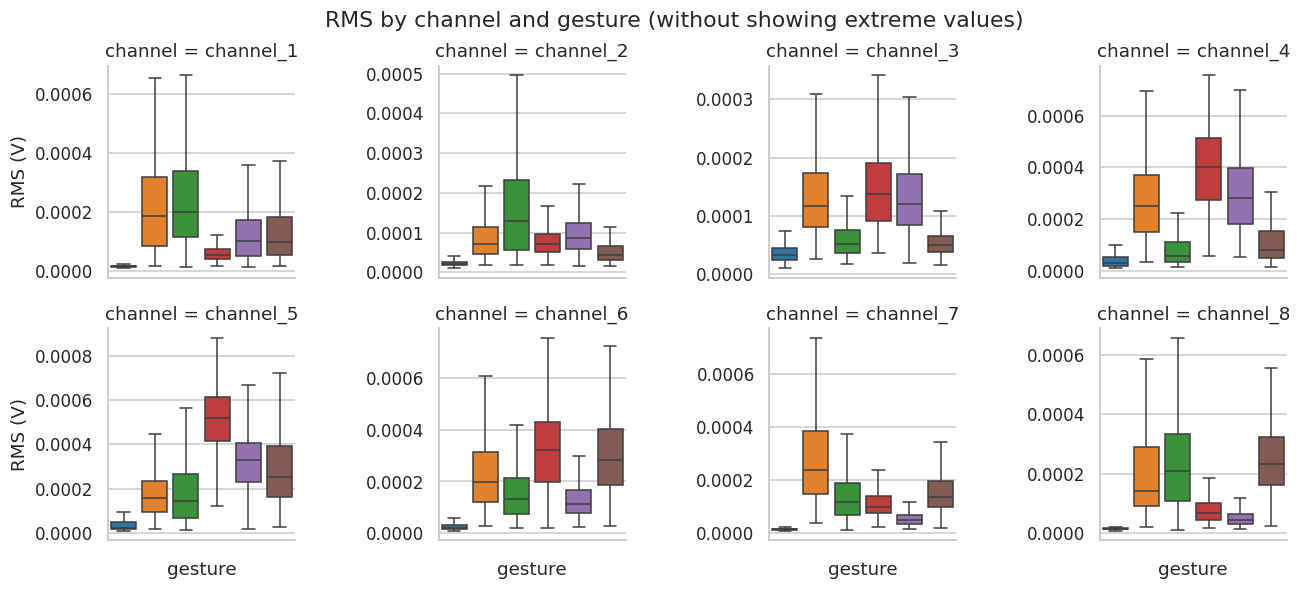

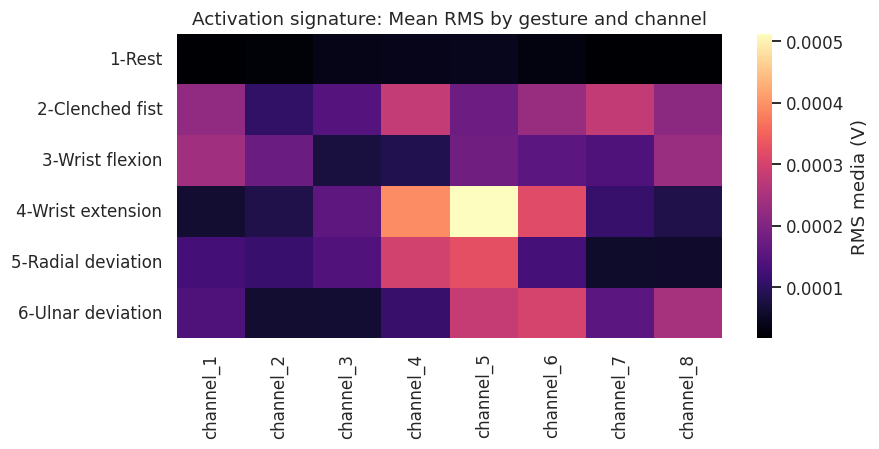

In [33]:
rms_cols = [f"RMS_{c}" for c in channels]
length = F_all[rms_cols].copy()
length["gesture"] = pd.Series(y_all).map(lambda c: f"{c}-{GESTURE_NAMES[c]}").values
length = length.melt(id_vars="gesture", var_name="channel", value_name="RMS (V)")
length["channel"] = length["channel"].str.replace("RMS_", "")

g = sns.catplot(data=length, kind="box", x="gesture", y="RMS (V)", col="channel", col_wrap=4,
                sharey=False, showfliers=False, height=2.7, aspect=1.15, palette="tab10")
g.set_xticklabels(rotation=60, ha="right", fontsize=7)
g.fig.suptitle("RMS by channel and gesture (without showing extreme values)", y=1.02)
plt.show()

signature = F_all[rms_cols].groupby(y_all).mean()
signature.index = [f"{c}-{GESTURE_NAMES[c]}" for c in signature.index]; signature.columns = channels
plt.figure(figsize=(8, 3.6))
sns.heatmap(signature, cmap="magma", cbar_kws={"label": "RMS media (V)"})
plt.title("Activation signature: Mean RMS by gesture and channel"); plt.show()

**Intra-subject variability.** The 40 standardised features are plotted using PCA, colour-coded by gesture and by subject, and the **silhouette** is measured using both labels.

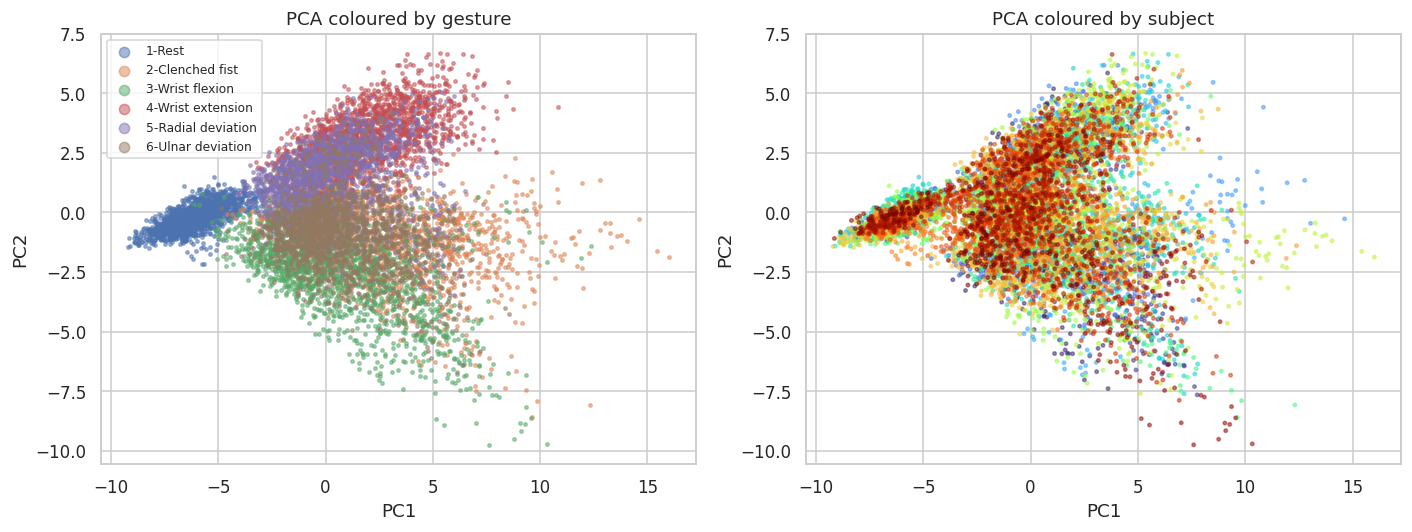

Gesture silhouette: 0.094
Subject silhouette: -0.098


In [34]:
rng = np.random.RandomState(SEED)
sub = rng.choice(len(F_all), size=min(4000, len(F_all)), replace=False)
Z = StandardScaler().fit_transform(F_all.values)
P = PCA(n_components=2, random_state=SEED).fit_transform(Z)
cod_suj = pd.factorize(g_all)[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in classes:
    m = y_all == c
    ax[0].scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, label=f"{c}-{GESTURE_NAMES[c]}")
ax[0].legend(markerscale=3, fontsize=8); ax[0].set_title("PCA coloured by gesture")
ax[1].scatter(P[:, 0], P[:, 1], c=cod_suj, cmap="turbo", s=5, alpha=0.5)
ax[1].set_title("PCA coloured by subject")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

print(f"Gesture silhouette: {silhouette_score(Z[sub], y_all[sub]):.3f}")
print(f"Subject silhouette: {silhouette_score(Z[sub], cod_suj[sub]):.3f}")

Both silhouettes are low (0.094 per gesture and −0.098 per subject): in two components, neither gestures nor subjects form compact clusters, meaning that the gestures cannot be separated by a simple linear projection and models with non-linear boundaries are required. The negative silhouette per subject indicates that subject identity does not form compact clusters; however, Section 4.11 shows that inter-subject variability does limit performance.

## 4.5 Partition by subject

* **Test (hold-out):** ≈ 20 per cent of the **subjects**, chosen at random and set aside until Section 4.10.
* **Training:** the remaining 80 per cent, using `StratifiedGroupKFold` with 5 partitions: this never splits the same individual between training and validation and maintains the class proportions approximately.

This simulates the real-world scenario: a **new user** whose data the model has not seen.

In [36]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_tr, idx_te = next(gss.split(F_all, y_all, groups=g_all))

F_tr, y_tr, g_tr = F_all.iloc[idx_tr], y_all[idx_tr], g_all[idx_tr]
F_te, y_te, g_te = F_all.iloc[idx_te], y_all[idx_te], g_all[idx_te]
assert set(g_tr).isdisjoint(set(g_te)), "There are subjects in both the training and test sets!"

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

resumen = pd.DataFrame({"subjects": [len(set(g_tr)), len(set(g_te))],
                        "windows": [len(y_tr), len(y_te)]}, index=["Training", "Test (hold-out)"])
dist = pd.DataFrame({"Training": pd.Series(y_tr).value_counts(normalize=True).sort_index(),
                     "Test": pd.Series(y_te).value_counts(normalize=True).sort_index()}).mul(100).round(1)
dist.index = [f"{c}-{GESTURE_NAMES[c]}" for c in dist.index]
display(resumen); display(dist.rename_axis("% of windows per class"))

,subjects,windows
Training,28,7576
Test (hold-out),8,2414


,Training,Test
% of windows per class,,
1-Rest,16.8,17.7
2-Clenched fist,16.7,15.8
3-Wrist flexion,16.3,16.9
4-Wrist extension,17.4,15.2
5-Radial deviation,16.2,16.3
6-Ulnar deviation,16.5,18.1


## 4.6 Initial model comparison

First, all models are evaluated using reasonable default hyperparameters, via subject-based cross-validation on the training set. Training performance is also reported to detect overfitting.

,F1-macro (val),± F1,Accuracy (val),Balanced accuracy (val),F1-macro (train),Training time (s)
Model,,,,,,
Dummy,0.049,0.001,0.174,0.167,0.049,0.007
Logistic regression,0.786,0.097,0.787,0.787,0.870,1.028
kNN,0.782,0.070,0.783,0.783,0.931,0.033
SVM (RBF),0.821,0.078,0.821,0.822,0.954,1.394
Random Forest,0.819,0.073,0.819,0.818,1.000,8.447
HistGradientBoosting,0.816,0.085,0.815,0.814,1.000,7.169


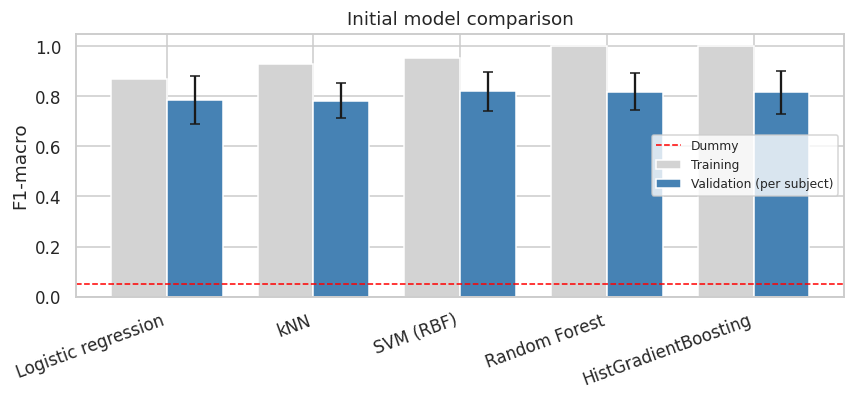

In [37]:
def pipe(clf, scaler=True):
    steps = ([("sc", StandardScaler())] if scaler else []) + [("clf", clf)]
    return Pipeline(steps)

models = {
    "Dummy":                pipe(DummyClassifier(strategy="most_frequent"), scaler=False),
    "Logistic regression":  pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
    "kNN":                  pipe(KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":            pipe(SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)),
    "Random Forest":        pipe(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), scaler=False),
    "HistGradientBoosting": pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), scaler=False),
}
scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy", "bal_acc": "balanced_accuracy"}

rows = []
for name, m in models.items():
    r = cross_validate(m, F_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    rows.append({"Model": name,
                  "F1-macro (val)": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
                  "Accuracy (val)": r["test_accuracy"].mean(),
                  "Balanced accuracy (val)": r["test_bal_acc"].mean(),
                  "F1-macro (train)": r["train_f1_macro"].mean(),
                  "Training time (s)": r["fit_time"].mean()})
base_table = pd.DataFrame(rows).set_index("Model").round(3)
display(base_table)

fig, ax = plt.subplots(figsize=(8, 3.8))
t = base_table.drop(index="Dummy"); x = np.arange(len(t)); w = 0.38
ax.bar(x - w/2, t["F1-macro (train)"], w, label="Training", color="lightgray")
ax.bar(x + w/2, t["F1-macro (val)"], w, yerr=t["± F1"], capsize=3, label="Validation (per subject)", color="steelblue")
ax.axhline(base_table.loc["Dummy", "F1-macro (val)"], color="red", ls="--", lw=1, label="Dummy")
ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=20, ha="right")
ax.set_ylabel("F1-macro"); ax.set_title("Initial model comparison"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* All models **clearly outperform the Dummy model** (F1-macro 0.05).
* The **logistic regression** (linear) performs worse than the non-linear models: the relationship between features and gesture is markedly non-linear.
* **SVM, Random Forest and HistGradientBoosting** are almost neck and neck in validation (≈ 0.82).
* There is a **significant gap between training and validation** (ensembles reach 1.0 in training): the models memorise the training subjects, which indicates that inter-subject variability is the main challenge.

## 4.7 Hyperparameter tuning

* **Strategy:** `GridSearchCV` (full grid) for logistic regression, kNN and SVM; `RandomizedSearchCV` (12 combinations) for tree ensembles, which have a larger search space.
* **Validation:** the same `StratifiedGroupKFold` per subject, always within the training set. Scaling takes place within the `Pipeline`, with no information leakage.
* **Selection metric:** macro-F1.
* **Ranges:** logarithmic for `C` and `gamma`, odd values for `n_neighbours` and increasing depths in the trees.

In [41]:
searches_cfg = {
    "Logistic regression": (GridSearchCV, pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
        {"clf__C": [0.01, 0.1, 1, 10, 100]}, {}),
    "kNN": (GridSearchCV, pipe(KNeighborsClassifier()),
        {"clf__n_neighbors": [3, 5, 9, 15, 25, 41], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}, {}),
    "SVM (RBF)": (GridSearchCV, pipe(SVC(kernel="rbf", random_state=SEED)),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": [0.003, 0.01, 0.03, 0.1, 0.3]}, {}),
    "Random Forest": (RandomizedSearchCV, pipe(RandomForestClassifier(n_jobs=-1, random_state=SEED), scaler=False),
        {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [None, 5, 10, 20],
         "clf__min_samples_leaf": [1, 2, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]}, {"n_iter": 12}),
    "HistGradientBoosting": (RandomizedSearchCV, pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), scaler=False),
        {"clf__learning_rate": [0.03, 0.1, 0.3], "clf__max_iter": [100, 200, 400],
         "clf__max_leaf_nodes": [15, 31, 63], "clf__l2_regularization": [0, 1, 10]}, {"n_iter": 12}),
}

searches = {}
for name, (Searcher, est, grid, extra) in searches_cfg.items():
    kw = dict(scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"}, refit="f1_macro",
              cv=cv, n_jobs=-1, return_train_score=True)
    if Searcher is RandomizedSearchCV: kw["random_state"] = SEED
    b = Searcher(est, grid, **kw, **extra)
    b.fit(F_tr, y_tr, groups=g_tr)
    searches[name] = b
    print(f"✔ {name}: {len(b.cv_results_['params'])} combinations evaluated")

✔ Logistic regression: 5 combinations evaluated
✔ kNN: 24 combinations evaluated
✔ SVM (RBF): 20 combinations evaluated
✔ Random Forest: 12 combinations evaluated
✔ HistGradientBoosting: 12 combinations evaluated


In [42]:
rows = []
for name, b in searches.items():
    i = b.best_index_
    rows.append({"Model": name,
                  "F1-macro (val)": b.cv_results_["mean_test_f1_macro"][i],
                  "± F1": b.cv_results_["std_test_f1_macro"][i],
                  "Accuracy (val)": b.cv_results_["mean_test_accuracy"][i],
                  "F1-macro (train)": b.cv_results_["mean_train_f1_macro"][i],
                  "Best hyperparameters’": {k.replace("clf__", ""): v for k, v in b.best_params_.items()}})
search_table = pd.DataFrame(rows).set_index("Model")
num = ["F1-macro (val)", "± F1", "Accuracy (val)", "F1-macro (train)"]
search_table[num] = search_table[num].round(3)
pd.set_option("display.max_colwidth", 120)
display(search_table)

improvement = pd.DataFrame({"Default": base_table["F1-macro (val)"],
                       "Adjusted": search_table["F1-macro (val)"]}).dropna()
improvement["Improvement"] = improvement["Adjusted"] - improvement["Default"]
display(improvement.round(3))

,F1-macro (val),± F1,Accuracy (val),F1-macro (train),Best hyperparameters’
Model,,,,,
Logistic regression,0.800,0.091,0.800,0.851,{'C': 0.01}
kNN,0.808,0.067,0.809,0.933,"{'n_neighbors': 41, 'p': 1, 'weights': 'uniform'}"
SVM (RBF),0.821,0.076,0.822,0.960,"{'C': 1, 'gamma': 0.03}"
Random Forest,0.820,0.073,0.820,0.978,"{'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}"
HistGradientBoosting,0.819,0.084,0.818,1.000,"{'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 10}"


,Default,Adjusted,Improvement
Model,,,
HistGradientBoosting,0.816,0.819,0.003
Logistic regression,0.786,0.800,0.014
Random Forest,0.819,0.820,0.001
SVM (RBF),0.821,0.821,0.000
kNN,0.782,0.808,0.026


The fit improves only slightly: the most notable improvements are seen in kNN (+0.026) and logistic regression (+0.014), whilst SVM and Random Forest remain virtually unchanged from their default values. The full SVM grid:

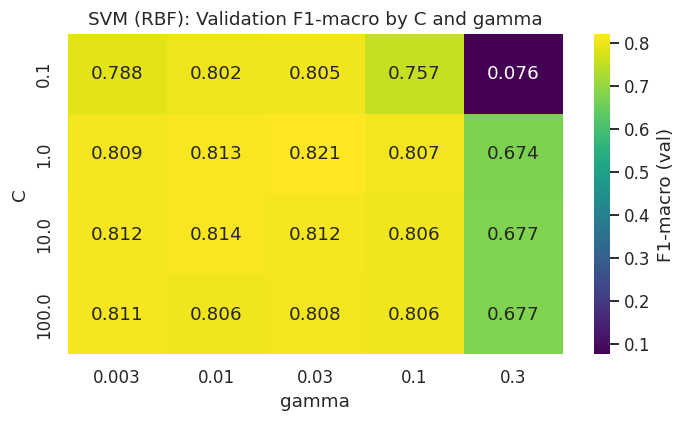

In [49]:
cr = pd.DataFrame(searches["SVM (RBF)"].cv_results_)
piv = cr.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_f1_macro")
plt.figure(figsize=(6.5, 4))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "F1-macro (val)"})
plt.title("SVM (RBF): Validation F1-macro by C and gamma")
plt.xlabel("gamma"); plt.ylabel("C"); plt.tight_layout(); plt.show()

## 4.8 Validation and training curves

**Validation curves.** Each curve varies *one* hyperparameter whilst keeping the rest at their optimal values, with the metric calculated for training and validation on a per-subject basis (range: ± 1 standard deviation across partitions).

In [52]:
import sklearn
import inspect
from sklearn.model_selection import validation_curve

print("Scikit-learn:", sklearn.__version__)
print("Función:", validation_curve)
print("Firma:", inspect.signature(validation_curve))

Scikit-learn: 1.6.1
Función: <function validation_curve at 0x7f32c85da700>
Firma: (estimator, X, y, *, param_name, param_range, groups=None, cv=None, scoring=None, n_jobs=None, pre_dispatch='all', verbose=0, error_score=nan, fit_params=None, params=None)


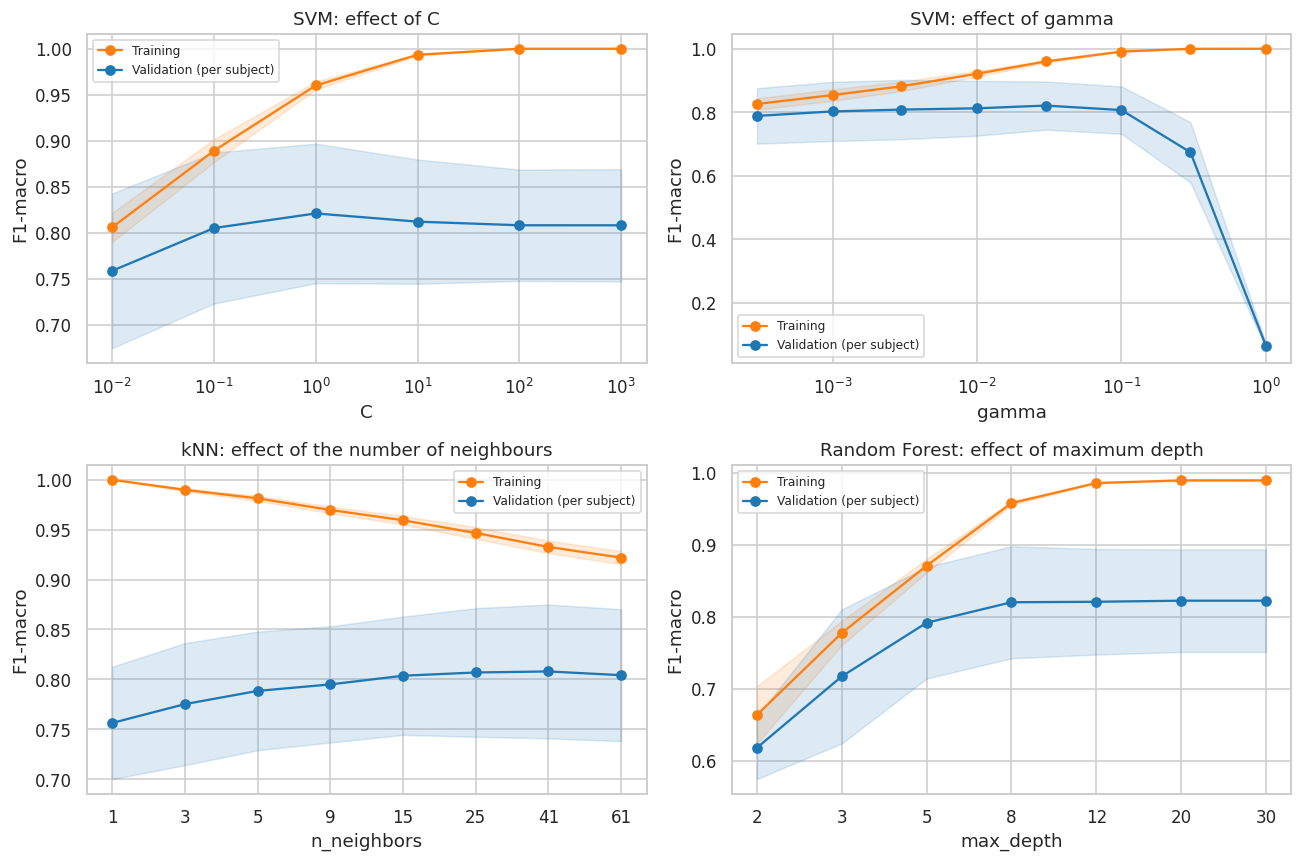

In [53]:
def plot_validation_curve(ax, estimator, param, param_range, title, log=False):

    ent, val = validation_curve(estimator, F_tr, y_tr, param_name=param, param_range=param_range,
                                groups=g_tr, cv=cv, scoring="f1_macro", n_jobs=-1)

    xs = np.array(param_range, dtype=float) if log else np.arange(len(param_range))

    for data, label, colour in [(ent, "Training", "tab:orange"), (val, "Validation (per subject)", "tab:blue")]:
        m, s = data.mean(1), data.std(1)  # Usamos 'data' (coherente con el bucle)
        ax.plot(xs, m, "o-", label=label, color=colour)
        ax.fill_between(xs, m - s, m + s, alpha=0.15, color=colour)

    if log:
        ax.set_xscale("log")
    else:
        ax.set_xticks(xs)
        ax.set_xticklabels([str(r) for r in param_range])

    ax.set_title(title)
    ax.set_xlabel(param.replace("clf__", ""))
    ax.set_ylabel("F1-macro")
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_validation_curve(axes[0, 0], clone(searches["SVM (RBF)"].best_estimator_), "clf__C",
                      [0.01, 0.1, 1, 10, 100, 1000], "SVM: effect of C", log=True)
plot_validation_curve(axes[0, 1], clone(searches["SVM (RBF)"].best_estimator_), "clf__gamma",
                      [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1], "SVM: effect of gamma", log=True)
plot_validation_curve(axes[1, 0], clone(searches["kNN"].best_estimator_), "clf__n_neighbors",
                      [1, 3, 5, 9, 15, 25, 41, 61], "kNN: effect of the number of neighbours")
plot_validation_curve(axes[1, 1], clone(searches["Random Forest"].best_estimator_), "clf__max_depth",
                      [2, 3, 5, 8, 12, 20, 30], "Random Forest: effect of maximum depth")

plt.tight_layout()
plt.show()

* **SVM, `C`:** with a low value of `C`, there is underfitting; validation reaches its maximum around `C` = 1 and, as `C` is increased, the training loss reaches 1.0 without any improvement in validation: overfitting with no gain.
* **SVM, `gamma`:** validation remains stable up to `gamma` ≈ 0.1 and drops sharply for higher values (the boundary becomes too local); `gamma` = 0.03 is near the peak.
* **kNN:** more neighbours smooth the decision boundary and slowly improve validation, until it stabilises around 25–41.
* **Random Forest:** with a depth ≤ 5 there is underfitting; from ≈ 8 the validation stabilises (≈ 0.82) whilst training continues to improve.

**Learning curves** for the two best models: how performance changes as the number of training windows increases (the partitions respect the groups by subject).

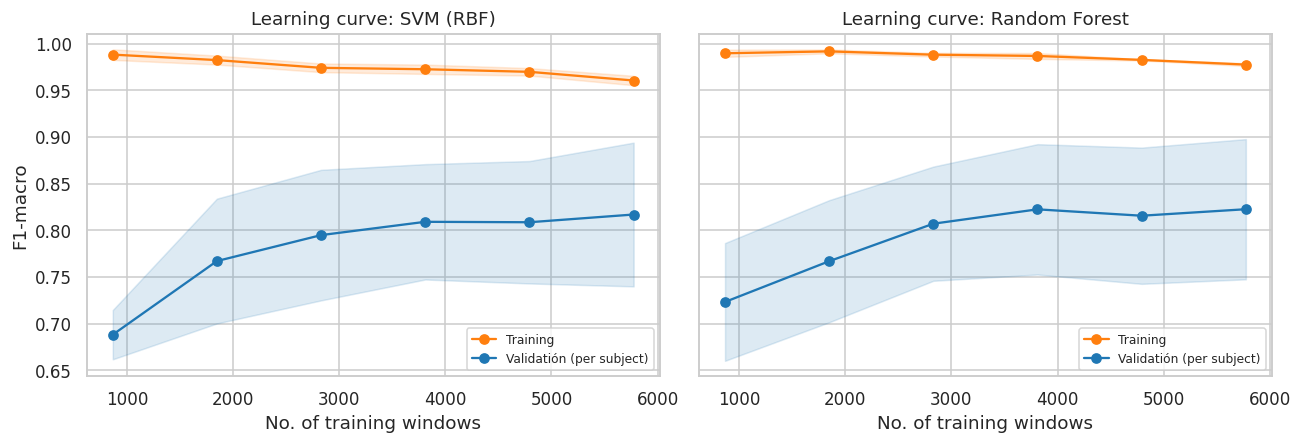

In [56]:
top_two = search_table["F1-macro (val)"].sort_values(ascending=False).index[:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name in zip(axes, top_two):
    tam, ent, val = learning_curve(clone(searches[name].best_estimator_), F_tr, y_tr,
                                   groups=g_tr, cv=cv, scoring="f1_macro",
                                   train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1, random_state=SEED)
    for data, label, colour  in [(ent, "Training", "tab:orange"), (val, "Validatión (per subject)", "tab:blue")]:
        m, s = data.mean(1), data.std(1)
        ax.plot(tam, m, "o-", label=label, color=colour)
        ax.fill_between(tam, m - s, m + s, alpha=0.15, color=colour)
    ax.set_title(f"Learning curve: {name}"); ax.set_xlabel("No. of training windows"); ax.legend(fontsize=8)
axes[0].set_ylabel("F1-macro")
plt.tight_layout(); plt.show()

Validation rises to around 3,800 windows and then **flattens out** (≈ 0.82), whilst training remains close to 1.0. With these descriptors, **adding more windows from the same subjects would not improve the result**: the limit is set by inter-individual variability and the power of the features, so what would help is to incorporate *more subjects* or adapt the model to each user.

## 4.9 Model selection

**Selected model: SVM with RBF kernel, `C` = 1 and `gamma` = 0.03**, which achieved the highest mean macro-F1 score in cross-validation per subject (0.821 ± 0.076).

* This is a **technical tie** with Random Forest (0.820) and HistGradientBoosting (0.819): the differences are much smaller than the deviation between partitions (≈ 0.07–0.08).
* Among equivalent models, the SVM is preferred due to its slightly smaller training–validation gap (0.960 compared to 0.978 and 1.000 for the ensembles) and because it is very lightweight in terms of prediction (section 4.11).
* The selection was made **solely using cross-validation**, without examining the test set.

## 4.10 Evaluation on the test set

The selected model is evaluated **once** on the 8 reserved subjects, who were not involved in either the training or the selection of hyperparameters. Accuracy, precision, recall, F1 score, AUC (one-versus-all per class), confusion matrix and performance per subject are reported.

In [57]:
best_name = search_table["F1-macro (val)"].idxmax()
final_model = searches[best_name].best_estimator_      # already retrained with all training subjects
pred = final_model.predict(F_te)

def scores(model, X):
    return model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)

S = scores(final_model, F_te)
Yb = label_binarize(y_te, classes=classes)
auc_clase = [roc_auc_score(Yb[:, k], S[:, k]) for k in range(len(classes))]

metrics = pd.Series({
    "Accuracy": accuracy_score(y_te, pred),
    "Balanced accuracy": balanced_accuracy_score(y_te, pred),
    "Precision (macro)": precision_score(y_te, pred, average="macro"),
    "Recall (macro)": recall_score(y_te, pred, average="macro"),
    "F1-macro": f1_score(y_te, pred, average="macro"),
    "AUC (macro, one-versus-all)": np.mean(auc_clase)}, name=best_name).round(3)
print(f"Model evaluated on the test set: {best_name}")
display(metrics.to_frame())

rep = pd.DataFrame(classification_report(y_te, pred, target_names=[GESTURE_NAMES[c] for c in classes],
                                         output_dict=True)).T.round(3)
rep.loc[[GESTURE_NAMES[c] for c in classes], "AUC"] = np.round(auc_clase, 3)
display(rep)

Model evaluated on the test set: SVM (RBF)


,SVM (RBF)
Accuracy,0.829
Balanced accuracy,0.828
Precision (macro),0.835
Recall (macro),0.828
F1-macro,0.829
"AUC (macro, one-versus-all)",0.955


,precision,recall,f1-score,support,AUC
Rest,0.926,0.998,0.961,428.000,0.999
Clenched fist,0.775,0.795,0.785,381.000,0.963
Wrist flexion,0.701,0.767,0.732,407.000,0.907
Wrist extension,0.970,0.796,0.874,367.000,0.971
Radial deviation,0.788,0.860,0.822,393.000,0.974
Ulnar deviation,0.853,0.753,0.800,438.000,0.919
accuracy,0.829,0.829,0.829,0.829,NaN
macro avg,0.835,0.828,0.829,2414.000,NaN
weighted avg,0.835,0.829,0.830,2414.000,NaN


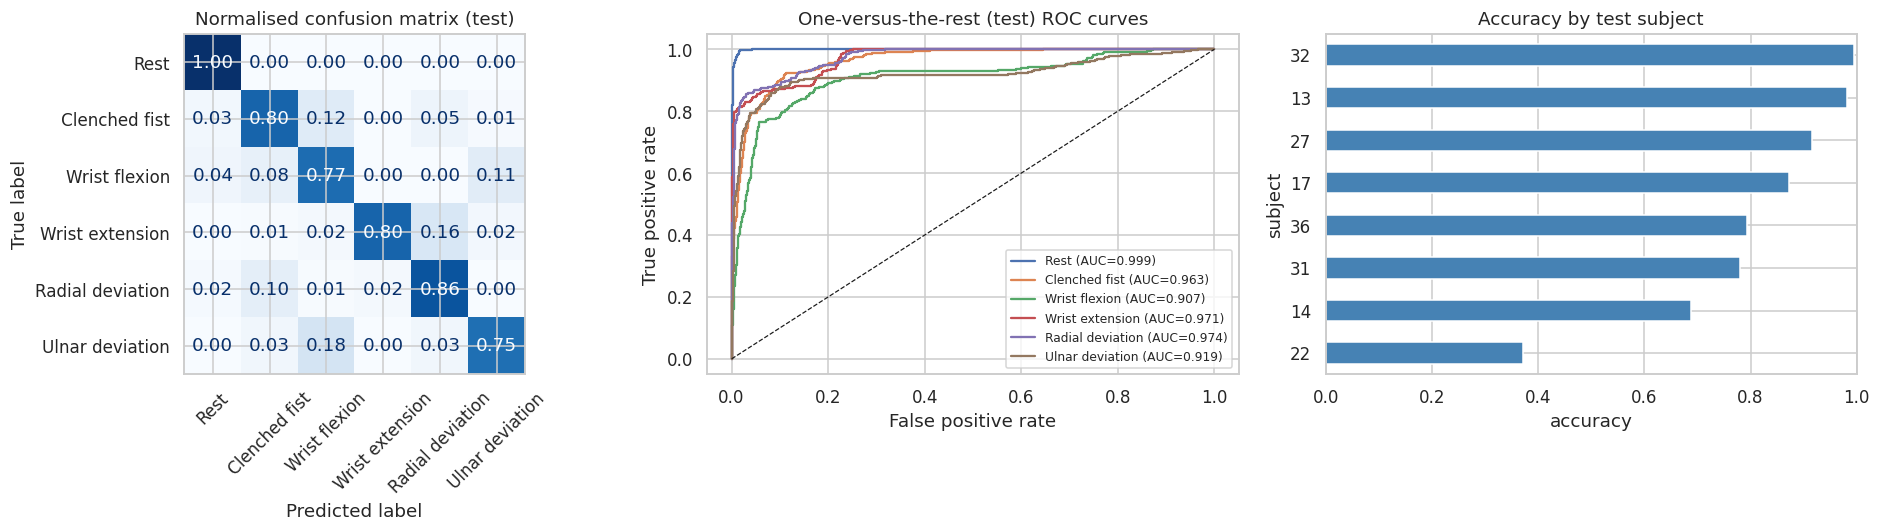

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, normalize="true", cmap="Blues", ax=ax[0],
        display_labels=[GESTURE_NAMES[c] for c in classes], xticks_rotation=45, values_format=".2f", colorbar=False)
ax[0].set_title("Normalised confusion matrix (test)")

for k, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Yb[:, k], S[:, k])
    ax[1].plot(fpr, tpr, label=f"{GESTURE_NAMES[c]} (AUC={auc_clase[k]:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("One-versus-the-rest (test) ROC curves"); ax[1].legend(fontsize=8)

por_suj = pd.DataFrame({"subject": g_te, "ok": (pred == y_te)}).groupby("subject")["ok"].mean().sort_values()
por_suj.plot.barh(ax=ax[2], color="steelblue")
ax[2].set_title("Accuracy by test subject"); ax[2].set_xlabel("accuracy"); ax[2].set_xlim(0, 1)
plt.tight_layout(); plt.show()

* **Overall performance:** F1-macro and accuracy of **0.83** with subjects the model had never seen before, very close to the cross-validation result (0.82): subject-based validation accurately estimated generalisation, and there was no overfitting due to the selection of training subjects.
* **By gesture:** the resting position is recognised almost perfectly (F1 0.96) and wrist extension is the best active gesture (F1 0.87). The most difficult gestures are **wrist flexion** (F1 0.73), the clenched fist (0.79) and ulnar deviation (0.80).
* **Errors:** these are concentrated in pairs of gestures that share the same musculature: wrist flexion ↔ ulnar deviation (11 per cent and 18 per cent), clenched fist → flexion (12 per cent) and extension → radial deviation (16 per cent).
* **AUC:** between 0.91 and 1.00 per gesture: the model effectively distinguishes each gesture from the rest, even when the final classification fails.
* **By subject:** accuracy ranges from ≈ 0.37 (subject 22) to ≈ 0.99 (subject 32). This variation is the main obstacle.

**Test performance of all fitted models** (for information only; not used for selection):

,Accuracy,Precision (macro),Recall (macro),F1-macro,F1-macro (CV)
Model,,,,,
Random Forest,0.856,0.861,0.856,0.856,0.819
Random Forest,0.856,0.863,0.856,0.856,0.820
Random Forest,0.829,0.835,0.828,0.829,0.821
Random Forest,0.828,0.831,0.827,0.827,0.808
Random Forest,0.817,0.821,0.816,0.816,0.800


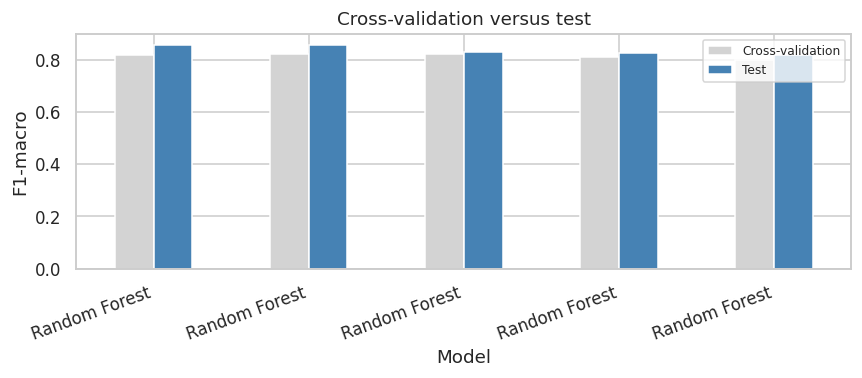

In [61]:
rows = []
for name, b in searches.items():
    p = b.best_estimator_.predict(F_te)
    rows.append({"Model": nombre, "Accuracy": accuracy_score(y_te, p),
                  "Precision (macro)": precision_score(y_te, p, average="macro"),
                  "Recall (macro)": recall_score(y_te, p, average="macro"),
                  "F1-macro": f1_score(y_te, p, average="macro"),
                  "F1-macro (CV)": b.cv_results_["mean_test_f1_macro"][b.best_index_]})
test_table = pd.DataFrame(rows).set_index("Model").sort_values("F1-macro", ascending=False).round(3)
display(test_table)

ax = test_table[["F1-macro (CV)", "F1-macro"]].plot.bar(figsize=(8, 3.6), color=["lightgray", "steelblue"])
ax.set_ylabel("F1-macro"); ax.set_title("Cross-validation versus test"); ax.legend(["Cross-validation", "Test"], fontsize=8)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

In the test set, Random Forest and HistGradientBoosting (0.856) perform slightly better than the SVM (0.829). This difference **is not used to alter the choice** (doing so would contaminate the test set) and, with only 8 subjects and the observed variation between subjects, it is consistent with the technical tie already shown by the cross-validation. What does hold true, however, is the overall picture: the non-linear models are clearly better than logistic regression, and all outperform the baseline.

**Examples of predictions** from the final model regarding the test subjects’ windows (no pre-trained model was used; the model was trained from scratch using the extracted features):

In [62]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(y_te), size=12, replace=False)
muestra = pd.DataFrame({"subject": g_te[idx], "real gesture": [GESTURE_NAMES[c] for c in y_te[idx]],
                        "predicted gesture": [GESTURE_NAMES[c] for c in pred[idx]]})
muestra["success?"] = np.where(y_te[idx] == pred[idx], "✔", "✘")
display(muestra.reset_index(drop=True))

,subject,real gesture,predicted gesture,success?
0,17,Wrist flexion,Wrist flexion,✔
1,36,Wrist extension,Wrist extension,✔
2,32,Ulnar deviation,Ulnar deviation,✔
3,31,Rest,Rest,✔
4,32,Rest,Rest,✔
5,14,Wrist flexion,Ulnar deviation,✘
6,13,Rest,Rest,✔
7,32,Wrist flexion,Wrist flexion,✔
8,27,Rest,Radial deviation,✘
9,31,Radial deviation,Radial deviation,✔


## 4.11 Model application and generalization capability

Generalization is analyzed from four perspectives: (a) performance with **each** subject treated as a new user, (b) whether **per-user calibration** is beneficial, (c) how the model handles a gesture it has **never encountered** before, and (d) its feasibility for **real-time** use.

### a) Each subject as a new user (LOSO)

Using the *Leave-One-Subject-Out* (LOSO) approach, the model is trained on 35 subjects and tested on the remaining one—a process repeated for all 36 subjects. This complements the *hold-out* method, which involves only 8 subjects.

LOSO - F1-global macro: 0.830 | accuracy: 0.831
F1-macro per subject: mean 0.815 | dev. 0.152 | min 0.315 | max 0.995


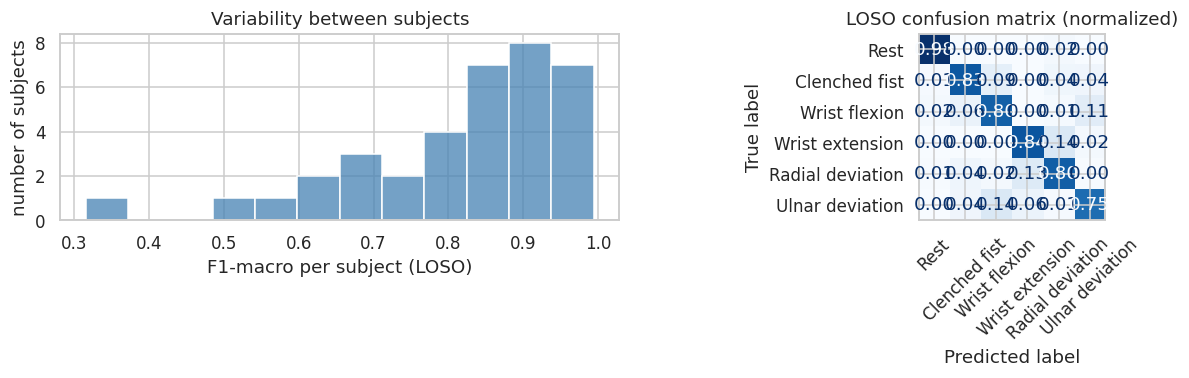

,5 most difficult subjects (F1-macro)
subject,
22,0.315
07,0.493
15,0.551
14,0.611
30,0.622


In [64]:
pred_loso = cross_val_predict(clone(final_model), F_all, y_all, groups=g_all, cv=LeaveOneGroupOut(), n_jobs=-1)
f1_suj = pd.DataFrame({"subject": g_all, "y": y_all, "p": pred_loso}).groupby("subject") \
           .apply(lambda d: f1_score(d["y"], d["p"], average="macro"))

print(f"LOSO - F1-global macro: {f1_score(y_all, pred_loso, average='macro'):.3f} | "
      f"accuracy: {accuracy_score(y_all, pred_loso):.3f}")
print(f"F1-macro per subject: mean {f1_suj.mean():.3f} | dev. {f1_suj.std():.3f} | min {f1_suj.min():.3f} | max {f1_suj.max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(f1_suj, bins=12, color="steelblue", ax=ax[0])
ax[0].set_xlabel("F1-macro per subject (LOSO)"); ax[0].set_ylabel("number of subjects"); ax[0].set_title("Variability between subjects")
ConfusionMatrixDisplay.from_predictions(y_all, pred_loso, normalize="true", cmap="Blues", ax=ax[1],
        display_labels=[GESTURE_NAMES[c] for c in classes], xticks_rotation=45, values_format=".2f", colorbar=False)
ax[1].set_title("LOSO confusion matrix (normalized)")
plt.tight_layout(); plt.show()
display(f1_suj.sort_values().head(5).round(3).rename("5 most difficult subjects (F1-macro)").to_frame())

The global macro-F1 score (0.830) matches that of the hold-out set, but it **varies significantly across individuals**: ranging from 0.32 to 0.99 (with a standard deviation of 0.15). While the model performs very well for most, there are certain subjects (such as 22, 07, or 15) for whom the general model performs poorly, indicating a need for adaptation.

### b) User-specific calibration: subject-based normalization

Standardizing features **within each subject** (using their own data windows, without labels) can help reduce the impact of inter-individual variability. In a real-world application, this is equivalent to a **brief calibration** phase for each new user. We compare global normalization against subject-based normalization, using the same model and hyperparameters.

In [66]:
def normalize_by_subject(F, subjects):
    F = F.astype(float).copy()
    for s in np.unique(subjects):
        m = subjects == s
        F.loc[m] = (F.loc[m] - F.loc[m].mean()) / (F.loc[m].std() + 1e-12)
    return F

F_norm = normalize_by_subject(F_all.reset_index(drop=True), g_all)
Fn_tr, Fn_te = F_norm.iloc[idx_tr], F_norm.iloc[idx_te]

rows = []
for label, (Ftr_, Fte_) in {"Global Normalization": (F_tr, F_te), "Subject Normalization": (Fn_tr, Fn_te)}.items():
    m = clone(final_model)
    r = cross_validate(m, Ftr_, y_tr, groups=g_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    p = clone(m).fit(Ftr_, y_tr).predict(Fte_)
    rows.append({"Variant": label, "F1-macro CV (val)": r["test_score"].mean(), "± F1": r["test_score"].std(),
                  "F1-macro test": f1_score(y_te, p, average="macro"), "Accuracy test": accuracy_score(y_te, p)})
display(pd.DataFrame(rows).set_index("Variant").round(3))

,F1-macro CV (val),± F1,F1-macro test,Accuracy test
Variant,,,,
Global Normalization,0.821,0.076,0.829,0.829
Subject Normalization,0.872,0.063,0.909,0.909


Subject-based normalization improves both cross-validation (0.821 → 0.872) and test performance (macro-F1 and accuracy: 0.829 → 0.909). **A brief initial calibration is a very promising strategy**. Caution: this was evaluated using only the 8 test subjects, and it requires obtaining data windows from a new user before classification can begin.

### c) An unseen gesture: Class 7

Class 7 (extended palm) was not included in the training or evaluation sets. We observe which known gestures the model assigns these windows to, which reveals how a closed-set classifier behaves when faced with a new, previously unseen gesture.

In [67]:
F7 = feature_extraction(X_class7)
p7 = final_model.predict(F7)
dist7 = pd.Series(p7).map(GESTURE_NAMES).value_counts(normalize=True).mul(100).round(1)
display(dist7.rename("% of class 7 windows assigned to each gesture").to_frame())

if hasattr(final_model, "predict_proba"):
    conf7 = final_model.predict_proba(F7).max(axis=1)
    conf_test = final_model.predict_proba(F_te).max(axis=1)
    plt.figure(figsize=(6, 3.2))
    sns.kdeplot(conf_test, label="Known gestures (test)", fill=True, alpha=0.3)
    sns.kdeplot(conf7, label="Class 7 (unseen)", fill=True, alpha=0.3)
    plt.xlabel("Maximum predicted probability"); plt.title("Model confidence"); plt.legend(); plt.tight_layout(); plt.show()

,% of class 7 windows assigned to each gesture
Ulnar deviation,82.0
Wrist extension,6.0
Wrist flexion,4.0
Radial deviation,4.0
Rest,2.0
Clenched fist,2.0


The model assigns the **majority (82%) of the windows from class 7 to ulnar deviation**, distributing the remainder among the other gestures. A closed-set classifier **always selects a class**, even if the gesture is unknown. For practical application, one would need to incorporate a **confidence threshold** or an "unknown" class (with the current SVM, which lacks probabilistic output, it was not possible to compare confidence levels), and collect data from more subjects for class 7 in order to include it.

### d) Practical application: real-time recognition

A real-world system receives a new window approximately every 100 ms (a 50% step size over a 200 ms duration). The complete inference function (raw window → features → gesture) is defined, and its latency is measured.

In [75]:
def recognize_gesture(window, model=final_model):
    # window: array (25, 8) containing raw voltages from 8 channels
    f = feature_extraction(np.asarray(window)[None, :, :])
    c = int(model.predict(f)[0])
    return c, GESTURE_NAMES[c]

# Example using a test window
i = 0
idx_global = np.where(mask)[0][idx_te][i]
print("Real gesture :", GESTURE_NAMES[int(y_te[i])])
print("Predicted gesture :", recognize_gesture(X_windows[idx_global])[1])

# Inference latency (feature extraction + prediction)
v = X_windows[idx_global]
recognize_gesture(v)                             # warm-up
t0 = time.perf_counter()
n_rep = 200
for _ in range(n_rep): recognize_gesture(v)
lat = (time.perf_counter() - t0) / n_rep * 1000
print(f"\nAverage latency per window: {lat:.2f} ms (available margin between windows: ~100 ms)")

reps, n_rep = 5, 200
times = []
for _ in range(reps):
    t0 = time.perf_counter()
    for _ in range(n_rep): recognize_gesture(v)
    times.append((time.perf_counter() - t0) / n_rep * 1000)
lat = np.median(times)
print(f"\nMedian latency per window: {lat:.2f} ms (range {min(times):.2f}–{max(times):.2f} ms; available margin between windows: ~100 ms)")

Real gesture : Rest
Predicted gesture : Rest

Average latency per window: 2.97 ms (available margin between windows: ~100 ms)

Median latency per window: 2.95 ms (range 2.84–3.21 ms; available margin between windows: ~100 ms)


Inference takes ≈ 3 ms per window, compared to the ≈ 100 ms available; the model is **viable for real-time control** (the total system latency, including acquisition and actuation, is outside the scope of this study).

---
# 5. Conclusions

**Answer to the project research question.** Using 40 time-domain features and an SVM with an RBF kernel, it is possible to recognize six hand and wrist gestures in unseen individuals with an **F1-macro ≈ 0.83** (compared to a baseline of 0.05). While this serves as a sufficient starting point for a controller, it is not a final solution, as performance is highly dependent on the individual (ranging from 0.32 to 0.99 per subject).

## 5.1 Fulfillment of success criteria

| Criterion (Phase 1) | Result |
|---|---|
| Clearly outperform baselines | **Met.** F1-macro of 0.829 and accuracy of 0.829, compared to 0.049 and 0.174 for the majority-class classifier (random guessing across 6 classes would yield ≈ 0.17 accuracy). |
| Evaluate using accuracy, F1-macro, and a confusion matrix | **Met.** Also includes precision, recall, AUC per gesture, balanced accuracy, and performance per subject. |
| Measure generalization to unseen subjects | **Met.** Used grouped cross-validation, an 8-subject hold-out set, and Leave-One-Subject-Out (LOSO) cross-validation across all 36 subjects, including an analysis of variance per subject. |

## 5.2 Key Findings

1. **Proper signal preparation was just as important as the model itself:** collapsing repeated readings (89% of the rows) revealed the true effective frequency (≈ 125 Hz), which dictates the window size and rules out frequency-domain features.
2. **Subject-based validation is essential:** mixing subjects leads to inflated results, with models reaching 1.0 in training compared to ≈ 0.82 in validation.
3. **Non-linear models outperform linear ones,** though SVM, Random Forest, and Gradient Boosting perform virtually the same; hyperparameter tuning yielded little improvement.
4. **The primary obstacle is inter-individual variability,** not the amount of data: learning curves plateau, and **user-specific calibration** offers the most promising improvement (0.83 → 0.91 on the test set).
5. **Very low inference latency** (≈ 3 ms) relative to the ≈ 100 ms threshold.

## 5.3 Limitations

* Only **36 subjects** were included; the "open palm" class appeared in only 2 of them and was therefore excluded from the model.
* The test set consists of only **8 subjects**, leading to significant uncertainty in test metrics (accuracy per subject ranges from ≈ 0.37 to ≈ 0.99). Consequently, minor differences between models are inconclusive.
* The effective frequency (≈ 125 Hz) limits features to the **time domain**.
* It is a **closed-set classifier:** it always selects a gesture, even if the actual gesture is unknown.
* The effect of subject-specific normalization was evaluated only on the 8-subject hold-out set and assumes that data from a new user is available prior to classification.
* The evaluation was **offline:** it was not tested on an actual device, nor was the latency of the complete system measured.

## 5.4 Future Work

1. Evaluate **subject-wise normalization using LOSO** (Leave-One-Subject-Out) across all 36 subjects to confirm performance improvements with a more robust estimate.
2. Introduce an **"unknown" class** or a confidence threshold (by enabling probabilistic outputs), and incorporate "Class 7" using data from additional subjects.
3. Test **1D neural networks** on windowed signals, incorporating additional features and exploring different window sizes.
4. Estimate **confidence intervals** through subject-based resampling to allow for more rigorous model comparison.
5. Validate the system in **real-time** using an assistive device.

## 5.5 Changes from the Initial Plan

| Aspect | Initial Plan (Phase 1) | Final Outcome |
|---|---|---|
| Features | RMS, waveform length, and zero-crossings (3) | RMS, MAV, WL, ZC, and SSC per channel (5 → 40 variables) |
| Models | k-NN, SVM, and Random Forest | Added Logistic Regression, HistGradientBoosting, and a Dummy (baseline) model |
| Hyperparameters | "Only if time permits" | Grid search and random search with subject-grouped validation |
| Validation | Subject-based | Grouped CV (5-fold) + hold-out set (8 subjects) + LOSO |
| Class 7 | Out of scope | Excluded from the main model; analyzed as an "unknown" gesture |
| Real-time | Out of scope | Remains out of scope, though inference latency was measured |
| Sampling rate | — | 1 kHz nominal → ≈ 125 Hz effective (after collapsing repeated readings) | ---

## Credits

* **Professor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Teaching Assistant:** [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/)
* **Image Design:** [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/)
* **Virtualization Coordinator:** [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/)

**National University of Colombia** · *Faculty of Engineering*